# Diabetes Disease Progression Regression Study
ML Assignment: Understanding the data, EDA, adding a few useful features, comparing models, checking the final errors, and answering the main questions from the assignment.

## 1. Problem Statement and Evaluation Goal

The target variable is a continuous disease progression score, so this is a regression problem. In simple terms, the aim is to learn a function like:

```text
f(X) -> y_hat
```

Here, `X` contains the 10 baseline measurements, and `y_hat` is the predicted disease progression value.

We have used the following research questions from the assignment as the main guide for the analysis:

1. Which baseline characteristics have the strongest statistical association with disease progression?
2. How well can a linear model explain the variation in the target?
3. Does regularization improve generalization when predictors are correlated?
4. Do nonlinear models capture relationships that a linear model cannot?
5. How sensitive are the conclusions to the choice of model?
6. Which model provides the best balance between predictive accuracy and interpretability?

The direct answers are given in Section 13, after the EDA, feature engineering, model comparison, and diagnostics.

In [353]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy import stats

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT

pd.set_option("display.max_columns", 120)
pd.set_option("display.precision", 4)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {
    "teal": "#0B7285",
    "amber": "#F08C00",
    "indigo": "#5C7CFA",
    "green": "#2B8A3E",
    "red": "#C92A2A",
    "violet": "#862E9C",
    "gray": "#495057",
    "light": "#F8F9FA",
}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.titlesize": 13,
    "font.size": 10,
    "legend.frameon": False,
})


def tidy_number(value, digits=4):
    if isinstance(value, (np.floating, float)):
        return round(float(value), digits)
    if isinstance(value, (np.integer, int)):
        return int(value)
    return value


In [354]:
# ADDED: expose solver warnings and record the execution environment.
import copy
import hashlib
import importlib.metadata
import json
import sys
from datetime import datetime, timezone
from IPython.display import HTML
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import RepeatedKFold

warnings.resetwarnings()  # Overrides the retained blanket suppression in the original setup cell.
warnings.simplefilter('default')
warnings.simplefilter('always', ConvergenceWarning)
# Hide only this known plotting-API deprecation; retain numerical and convergence warnings.
warnings.filterwarnings('ignore', message=r'vert: bool will be deprecated.*',
                        category=PendingDeprecationWarning, module=r'seaborn[.]categorical')
environment_versions = {
    'python': sys.version.split()[0],
    **{p: importlib.metadata.version(p)
       for p in ['scikit-learn', 'numpy', 'scipy', 'pandas', 'matplotlib', 'seaborn']},
}
display(pd.Series(environment_versions, name='version').to_frame())
protocol_events = []


,version
python,3.13.12
scikit-learn,1.8.0
numpy,2.4.2
scipy,1.17.0
pandas,3.0.0
matplotlib,3.10.8
seaborn,0.13.2


## 2. Loading Diabetes Dataset and Data Dictionary

We are using the `load_diabetes` dataset from scikit-learn. It has 442 observations and 10 baseline variables. The variables in this dataset are already centered and scaled, but we still use scaling inside the model pipelines so that the same approach also works properly after feature engineering.

In [355]:
diabetes = load_diabetes(as_frame=True)
X_full = diabetes.data.copy()
y_full = diabetes.target.copy()
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.20, random_state=RANDOM_STATE
)
frozen_train_indices = tuple(X_train.index)
frozen_test_indices = tuple(X_test.index)
assert set(frozen_train_indices).isdisjoint(frozen_test_indices)
assert len(X_train) + len(X_test) == 442
X, y = X_train.copy(), y_train.copy()
protocol_events.append('split_before_target_informed_eda')
display(pd.DataFrame({'subset': ['Full dataset', 'Training / EDA', 'Reserved test'],
                      'rows': [len(X_full), len(X_train), len(X_test)]}))
display(pd.DataFrame({
    'feature': X_full.columns,
    'meaning': ['Age', 'Sex indicator', 'Body mass index', 'Average blood pressure',
                'Total serum cholesterol', 'Low-density lipoproteins', 'High-density lipoproteins',
                'Total cholesterol / HDL ratio', 'Log serum triglycerides', 'Blood sugar level'],
}))


,subset,rows
0,Full dataset,442
1,Training / EDA,353
2,Reserved test,89


,feature,meaning
0,age,Age
1,sex,Sex indicator
2,bmi,Body mass index
3,bp,Average blood pressure
4,s1,Total serum cholesterol
5,s2,Low-density lipoproteins
6,s3,High-density lipoproteins
7,s4,Total cholesterol / HDL ratio
8,s5,Log serum triglycerides
9,s6,Blood sugar level


## 3. Data Quality and Summary Statistics

Before fitting models, we first check the basic details of the data: number of rows and columns, missing values, summary statistics, and the range of the target. This gives a better idea of the scale of the prediction problem before looking at RMSE or MAE.

,count,mean,std,min,25%,50%,75%,max,missing,target_correlation
bmi,353.0,0.0017,0.0473,-0.0892,-0.0321,-0.0051,0.0326,0.1609,0,0.6048
s5,353.0,0.0012,0.0478,-0.1261,-0.0332,-0.0006,0.0337,0.1336,0,0.5522
bp,353.0,0.0012,0.0485,-0.1124,-0.0367,-0.0057,0.0356,0.1320,0,0.4448
s4,353.0,0.0004,0.0478,-0.0764,-0.0395,-0.0026,0.0343,0.1852,0,0.4251
s6,353.0,0.0019,0.0484,-0.1378,-0.0301,0.0031,0.0321,0.1356,0,0.3904
s3,353.0,-0.0010,0.0470,-0.1023,-0.0324,-0.0066,0.0266,0.1812,0,-0.3840
s1,353.0,-0.0006,0.0478,-0.1089,-0.0360,-0.0043,0.0260,0.1539,0,0.1995
age,353.0,0.0014,0.0463,-0.1072,-0.0309,0.0090,0.0381,0.1107,0,0.1965
s2,353.0,-0.0008,0.0476,-0.1156,-0.0326,-0.0041,0.0272,0.1988,0,0.1549
sex,353.0,0.0002,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507,0,0.0071


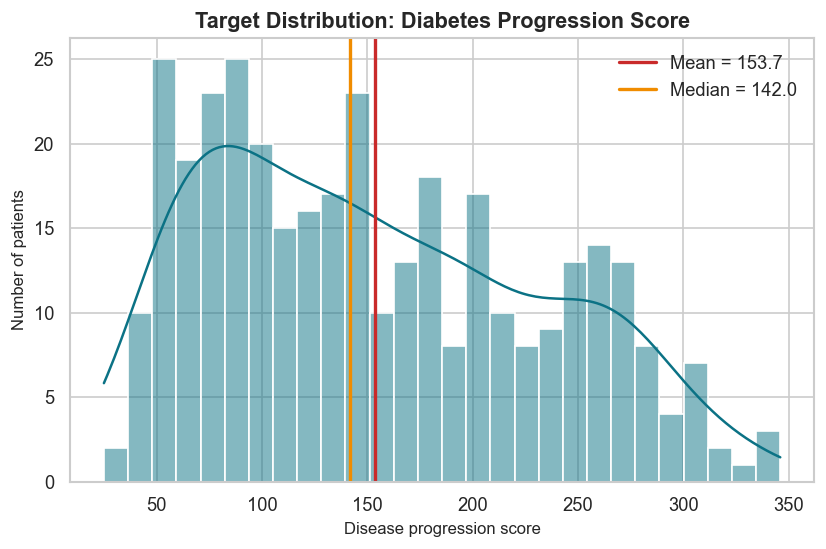

In [356]:
summary_stats = X.describe().T
summary_stats["missing"] = X.isna().sum()
summary_stats["target_correlation"] = X.corrwith(y).round(4)
summary_stats = summary_stats.sort_values("target_correlation", key=lambda s: s.abs(), ascending=False)
display(summary_stats)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(y, bins=28, kde=True, ax=ax, color=PALETTE["teal"], edgecolor="white")
ax.axvline(y.mean(), color=PALETTE["red"], linewidth=2, label=f"Mean = {y.mean():.1f}")
ax.axvline(y.median(), color=PALETTE["amber"], linewidth=2, label=f"Median = {y.median():.1f}")
ax.set_title("Target Distribution: Diabetes Progression Score")
ax.set_xlabel("Disease progression score")
ax.set_ylabel("Number of patients")
ax.legend()
plt.show()

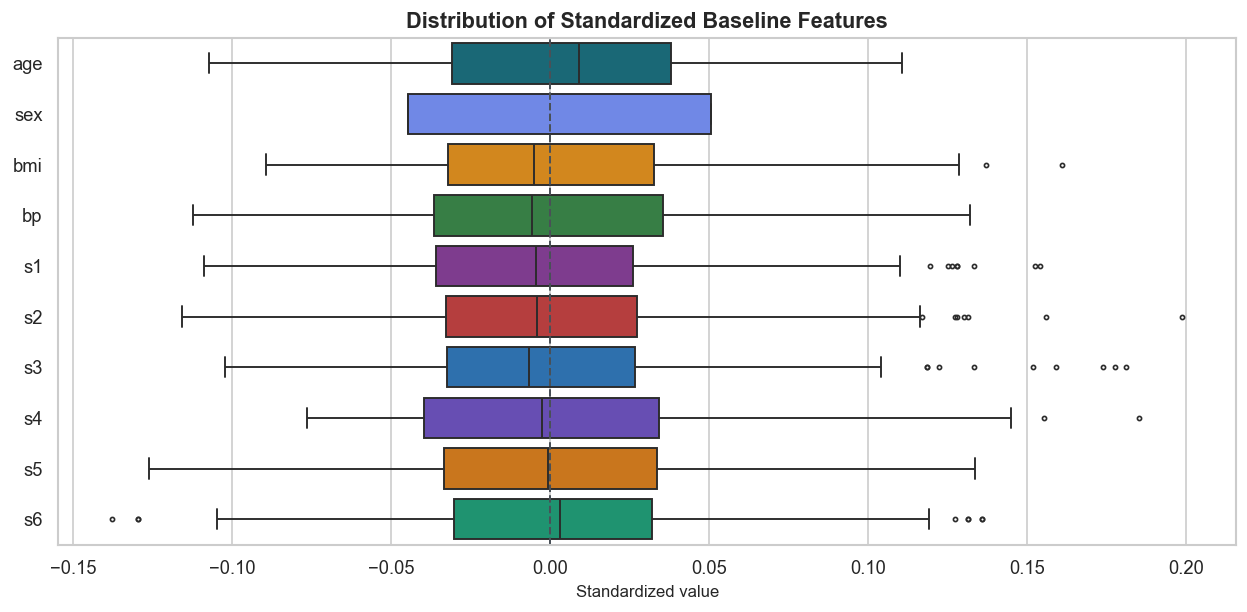

In [357]:
feature_long = X.melt(var_name="feature", value_name="standardized_value")

feature_box_palette = [
    PALETTE["teal"],
    PALETTE["indigo"],
    PALETTE["amber"],
    PALETTE["green"],
    PALETTE["violet"],
    PALETTE["red"],
    "#1971C2",
    "#5F3DC4",
    "#E67700",
    "#0CA678",
]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
sns.boxplot(
    data=feature_long,
    x="standardized_value",
    y="feature",
    hue="feature",
    palette=feature_box_palette,
    legend=False,
    ax=ax,
    fliersize=2.5,
    linewidth=1.15,
)
ax.axvline(0, color=PALETTE["gray"], linewidth=1.2, linestyle="--")
ax.set_title("Distribution of Standardized Baseline Features")
ax.set_xlabel("Standardized value")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis

In this part, we mainly look at two things:

- How each feature is related to the target.
- How the features are related to each other.

This is useful because strong feature-target relationships help prediction, while strong feature-feature relationships can create multicollinearity problems.

,pearson_correlation_with_target
bmi,0.6048
s5,0.5522
bp,0.4448
s4,0.4251
s6,0.3904
s3,-0.3840
s1,0.1995
age,0.1965
s2,0.1549
sex,0.0071


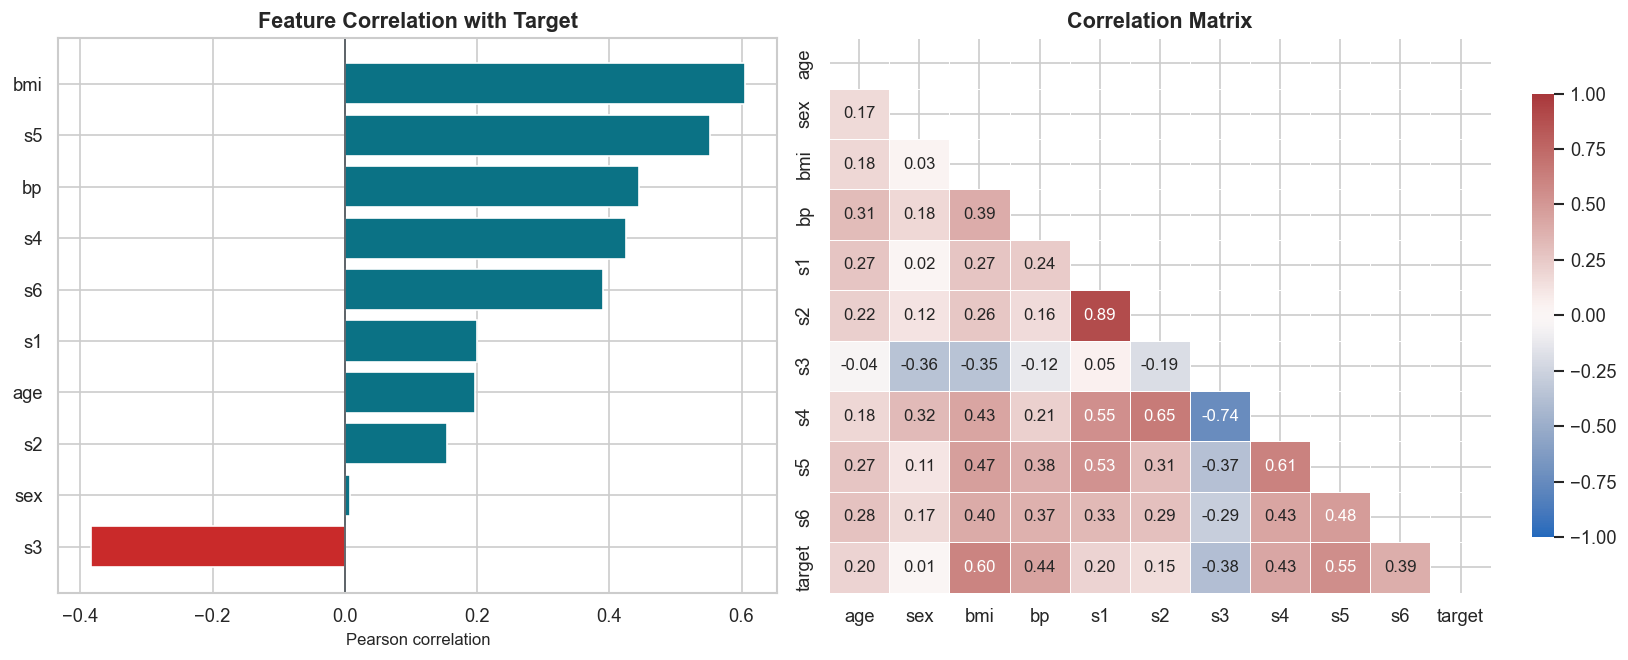

In [358]:
eda_df = X.copy()
eda_df["target"] = y

corr = eda_df.corr()
corr_with_target = corr["target"].drop("target").sort_values(key=lambda s: s.abs(), ascending=False)
display(corr_with_target.to_frame("pearson_correlation_with_target"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})

corr_plot = corr_with_target.sort_values()
colors = [PALETTE["red"] if value < 0 else PALETTE["teal"] for value in corr_plot]
axes[0].barh(corr_plot.index, corr_plot.values, color=colors)
axes[0].axvline(0, color=PALETTE["gray"], linewidth=1)
axes[0].set_title("Feature Correlation with Target")
axes[0].set_xlabel("Pearson correlation")
axes[0].set_ylabel("")

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[1],
)
axes[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

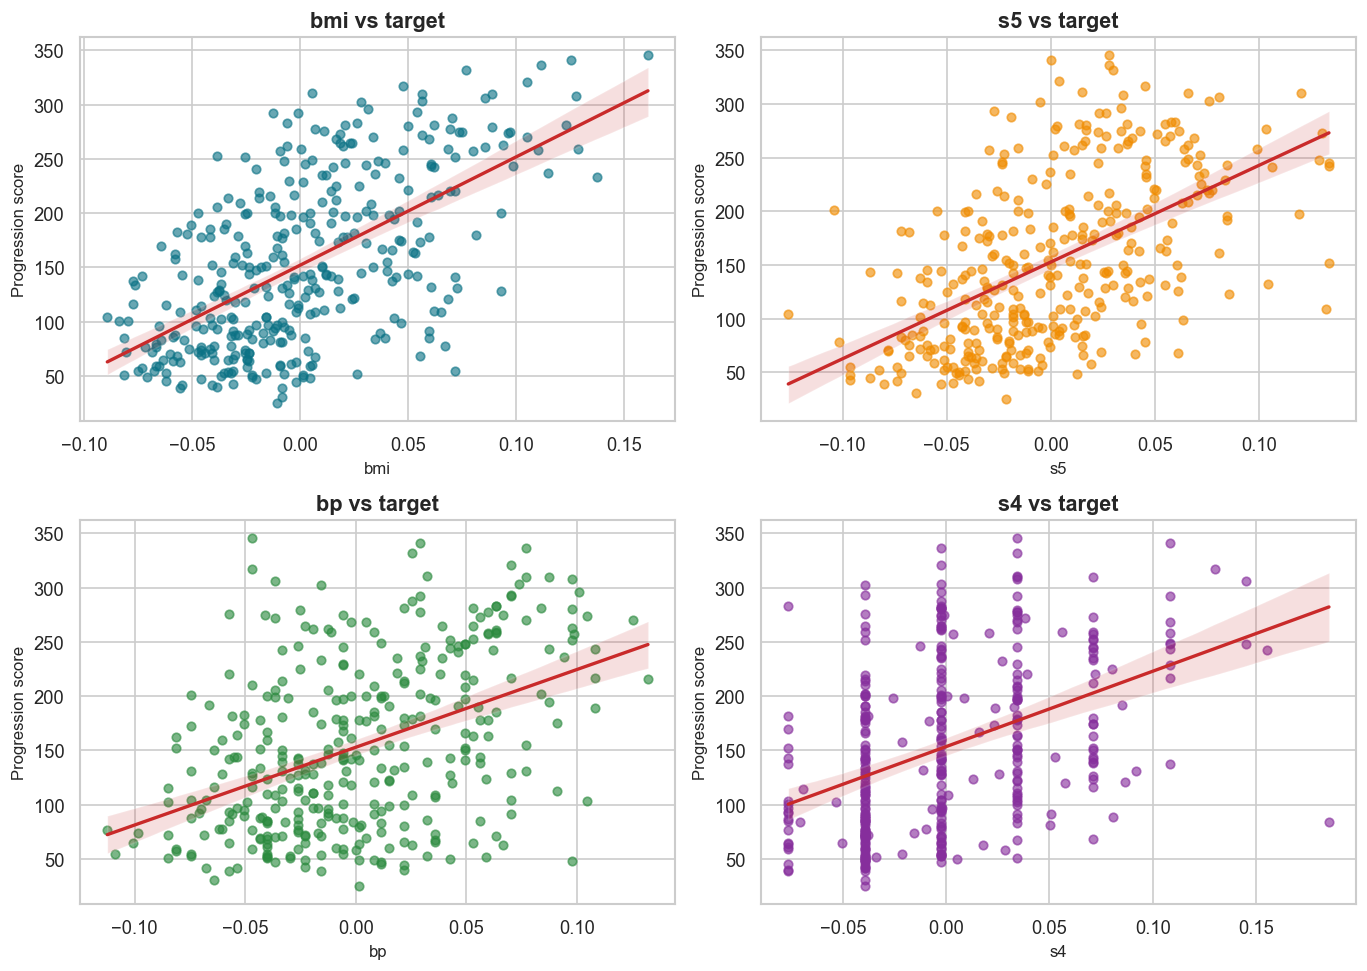

In [359]:
top_features = corr_with_target.abs().head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
axes = axes.ravel()
for ax, feature, color in zip(axes, top_features, [PALETTE["teal"], PALETTE["amber"], PALETTE["green"], PALETTE["violet"]]):
    sns.regplot(
        x=X[feature],
        y=y,
        ax=ax,
        scatter_kws={"alpha": 0.62, "s": 26, "color": color},
        line_kws={"color": PALETTE["red"], "linewidth": 2},
        ci=95,
    )
    ax.set_title(f"{feature} vs target")
    ax.set_xlabel(feature)
    ax.set_ylabel("Progression score")
plt.tight_layout()
plt.show()

## 5. Multicollinearity Check

Some of the serum measurements are closely related, so multicollinearity is expected. We use Variance Inflation Factor (VIF) to see how much one predictor can be explained by the other predictors. If VIF is high, it is a sign that Ridge or Lasso may be more stable than plain OLS.

,feature,r2_from_other_features,VIF
0,s1,0.9819,55.2521
1,s2,0.9720,35.7593
2,s3,0.9300,14.2856
3,s5,0.9007,10.0712
4,s4,0.8929,9.3330
5,bmi,0.3645,1.5736
6,s6,0.3336,1.5007
7,bp,0.2968,1.4221
8,sex,0.2119,1.2689
9,age,0.1784,1.2171


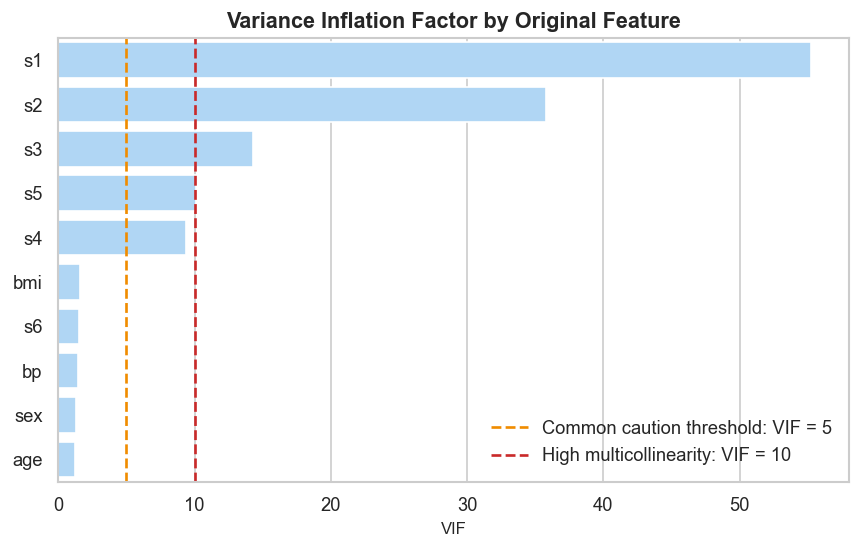

In [360]:
def calculate_vif(df):
    rows = []
    for feature in df.columns:
        other_features = [col for col in df.columns if col != feature]
        model = LinearRegression()
        model.fit(df[other_features], df[feature])
        r2 = model.score(df[other_features], df[feature])
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        rows.append({"feature": feature, "r2_from_other_features": r2, "VIF": vif})
    return pd.DataFrame(rows).sort_values("VIF", ascending=False).reset_index(drop=True)


vif_table = calculate_vif(X)
display(vif_table)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.barplot(data=vif_table, x="VIF", y="feature", ax=ax, color="#A5D8FF")
ax.axvline(5, color=PALETTE["amber"], linestyle="--", linewidth=1.6, label="Common caution threshold: VIF = 5")
ax.axvline(10, color=PALETTE["red"], linestyle="--", linewidth=1.6, label="High multicollinearity: VIF = 10")
ax.set_title("Variance Inflation Factor by Original Feature")
ax.set_xlabel("VIF")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.show()

## 6. Feature Engineering Strategy

For feature engineering, we have kept the extra features simple and interpretable first, and then we also add polynomial features to fully cover the usecase requirement. The manually added features include:

- Squared terms such as `bmi_squared`, `bp_squared`, and `s5_squared` to allow simple nonlinear effects.
- Interaction terms such as BMI with blood pressure, BMI with triglycerides, and blood pressure with triglycerides.
- A few combined lipid/metabolic features that may capture risk better than a single variable.

After this, we also compare polynomial feature sets of degree 2 and degree 3. This covers terms such as `x_i^2`, `x_i^3`, and interaction terms like `x_i x_j`. For each expanded feature setting, we compare OLS, Ridge, and Lasso so that the effect of feature engineering, model complexity, and regularization can be seen clearly.

All these features are created only from the input variables, so there is no leakage from the target.

In [361]:
def add_engineered_features(df):
    engineered = df.copy()
    engineered["bmi_squared"] = engineered["bmi"] ** 2
    engineered["bp_squared"] = engineered["bp"] ** 2
    engineered["s5_squared"] = engineered["s5"] ** 2
    engineered["bmi_x_bp"] = engineered["bmi"] * engineered["bp"]
    engineered["bmi_x_s5"] = engineered["bmi"] * engineered["s5"]
    engineered["bp_x_s5"] = engineered["bp"] * engineered["s5"]
    engineered["s3_x_s4"] = engineered["s3"] * engineered["s4"]
    engineered["lipid_balance_s1_minus_s3"] = engineered["s1"] - engineered["s3"]
    engineered["metabolic_risk_index"] = engineered[["bmi", "bp", "s5", "s6"]].mean(axis=1)
    return engineered


engineered_feature_guide = pd.DataFrame({
    "engineered_feature": [
        "bmi_squared",
        "bp_squared",
        "s5_squared",
        "bmi_x_bp",
        "bmi_x_s5",
        "bp_x_s5",
        "s3_x_s4",
        "lipid_balance_s1_minus_s3",
        "metabolic_risk_index",
    ],
    "reason": [
        "Allows a curved BMI-progress relationship.",
        "Allows nonlinear blood pressure effect.",
        "Allows nonlinear triglyceride-related effect.",
        "Captures joint BMI and blood pressure burden.",
        "Captures joint BMI and triglyceride burden.",
        "Captures combined blood pressure and triglyceride signal.",
        "Represents interaction between HDL and cholesterol ratio proxy.",
        "Contrasts total cholesterol proxy with HDL proxy.",
        "Compact average of BMI, blood pressure, triglycerides, and blood sugar.",
    ],
})
display(engineered_feature_guide)

,engineered_feature,reason
0,bmi_squared,Allows a curved BMI-progress relationship.
1,bp_squared,Allows nonlinear blood pressure effect.
2,s5_squared,Allows nonlinear triglyceride-related effect.
3,bmi_x_bp,Captures joint BMI and blood pressure burden.
4,bmi_x_s5,Captures joint BMI and triglyceride burden.
5,bp_x_s5,Captures combined blood pressure and triglyceride signal.
6,s3_x_s4,Represents interaction between HDL and cholesterol ratio proxy.
7,lipid_balance_s1_minus_s3,Contrasts total cholesterol proxy with HDL proxy.
8,metabolic_risk_index,"Compact average of BMI, blood pressure, triglycerides, and blood sugar."


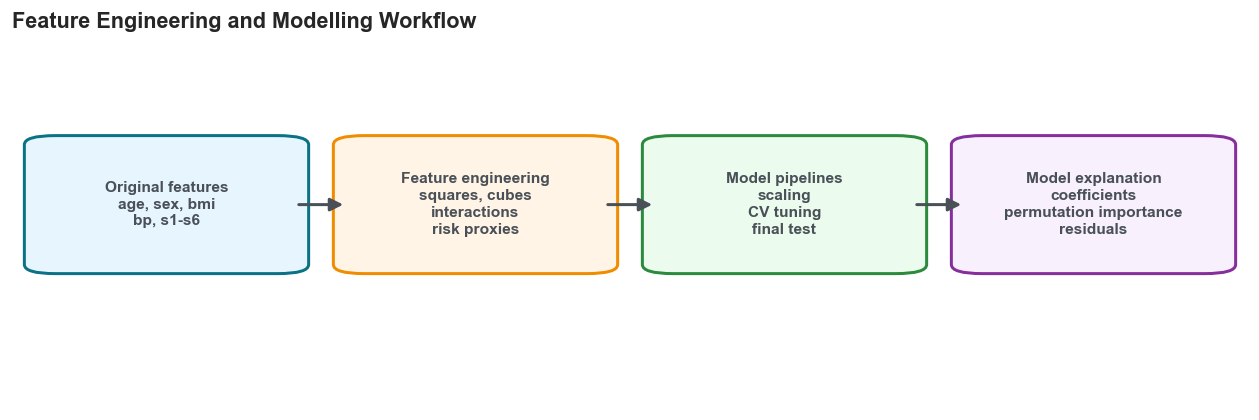

In [362]:
fig, ax = plt.subplots(figsize=(10.6, 3.6))
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

workflow_nodes = [
    {
        "text": "Original features\nage, sex, bmi\nbp, s1-s6",
        "xy": (0.03, 0.39),
        "color": PALETTE["teal"],
        "fill": "#E7F5FF",
    },
    {
        "text": "Feature engineering\nsquares, cubes\ninteractions\nrisk proxies",
        "xy": (0.28, 0.39),
        "color": PALETTE["amber"],
        "fill": "#FFF4E6",
    },
    {
        "text": "Model pipelines\nscaling\nCV tuning\nfinal test",
        "xy": (0.53, 0.39),
        "color": PALETTE["green"],
        "fill": "#EBFCEE",
    },
    {
        "text": "Model explanation\ncoefficients\npermutation importance\nresiduals",
        "xy": (0.78, 0.39),
        "color": PALETTE["violet"],
        "fill": "#F8F0FC",
    },
]

box_width = 0.19
box_height = 0.34

for node in workflow_nodes:
    x0, y0 = node["xy"]
    patch = FancyBboxPatch(
        (x0, y0),
        box_width,
        box_height,
        boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.8,
        edgecolor=node["color"],
        facecolor=node["fill"],
    )
    ax.add_patch(patch)
    ax.text(
        x0 + box_width / 2,
        y0 + box_height / 2,
        node["text"],
        ha="center",
        va="center",
        fontsize=9.3,
        color=PALETTE["gray"],
        weight="bold",
        linespacing=1.25,
    )

arrow_y = 0.56
for left_node, right_node in zip(workflow_nodes[:-1], workflow_nodes[1:]):
    start_x = left_node["xy"][0] + box_width + 0.012
    end_x = right_node["xy"][0] - 0.012
    ax.add_patch(
        FancyArrowPatch(
            (start_x, arrow_y),
            (end_x, arrow_y),
            arrowstyle="-|>",
            mutation_scale=16,
            linewidth=1.8,
            color=PALETTE["gray"],
            shrinkA=0,
            shrinkB=0,
        )
    )

ax.set_title("Feature Engineering and Modelling Workflow", loc="left", pad=10, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

,feature,correlation_with_target
0,metabolic_risk_index,0.6633
1,bmi,0.6048
2,s5,0.5522
3,bp,0.4448
4,s4,0.4251
5,lipid_balance_s1_minus_s3,0.4230
6,s6,0.3904
7,s3,-0.3840
8,bmi_squared,0.2958
9,s1,0.1995


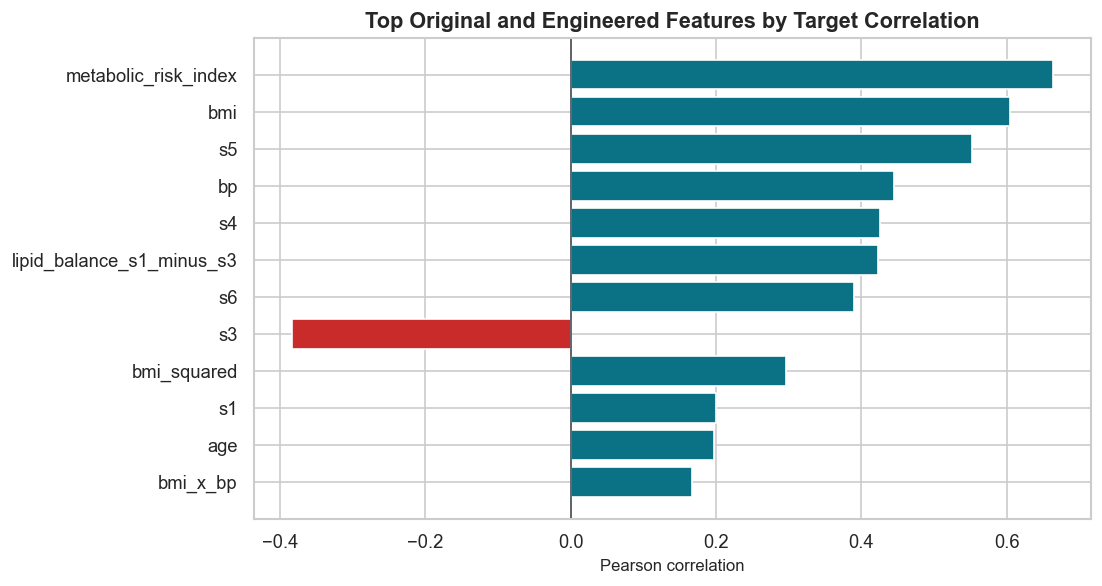

In [363]:
X_engineered = add_engineered_features(X)
engineered_corr = (
    X_engineered.corrwith(y)
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("correlation_with_target")
    .reset_index()
    .rename(columns={"index": "feature"})
)

display(engineered_corr.head(15))

fig, ax = plt.subplots(figsize=(9, 5.2))
plot_df = engineered_corr.head(12).iloc[::-1]
colors = [PALETTE["red"] if value < 0 else PALETTE["teal"] for value in plot_df["correlation_with_target"]]
ax.barh(plot_df["feature"], plot_df["correlation_with_target"], color=colors)
ax.axvline(0, color=PALETTE["gray"], linewidth=1)
ax.set_title("Top Original and Engineered Features by Target Correlation")
ax.set_xlabel("Pearson correlation")
ax.set_ylabel("")
plt.show()

## 7. Train-Test Split and Modelling Protocol

We keep a separate test set for the final evaluation. Model selection and hyperparameter tuning are done only on the training set using 5-fold cross-validation.

This is important because using the test set repeatedly for model selection would make the final performance look better than it really is.

In [364]:
# ADDED: retain training-only EDA evidence, then prepare the fixed modelling partitions.
assert tuple(X.index) == frozen_train_indices and tuple(y.index) == frozen_train_indices
eda_train_indices = tuple(X.index)
X, y = X_full.copy(), y_full.copy()
X_train_engineered = add_engineered_features(X_train)
X_test_engineered = add_engineered_features(X_test)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


In [365]:
assert tuple(X_train.index) == frozen_train_indices
assert tuple(X_test.index) == frozen_test_indices
assert tuple(y_train.index) == frozen_train_indices
assert tuple(y_test.index) == frozen_test_indices
protocol_events.append('training_partitions_verified_before_modeling')


In [366]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def make_poly_pipeline(model, degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


model_specs = {
    "DummyMean": {
        "feature_set": "original",
        "estimator": Pipeline([("model", DummyRegressor(strategy="mean"))]),
        "param_grid": {},
        "family": "baseline",
    },
    "OLS_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "param_grid": {},
        "family": "linear",
    },
    "Ridge_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Ridge(random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 3, 31)},
        "family": "regularized linear",
    },
    "Lasso_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "regularized linear",
    },
    "ElasticNet_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 1, 17), "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
        "family": "regularized linear",
    },
    "OLS_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "param_grid": {},
        "family": "feature engineered",
    },
    "Ridge_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Ridge(random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 4, 35)},
        "family": "feature engineered",
    },
    "Lasso_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "feature engineered",
    },
    "OLS_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(LinearRegression(), degree=2),
        "param_grid": {},
        "family": "polynomial degree 2",
    },
    "Ridge_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Ridge(random_state=RANDOM_STATE), degree=2),
        "param_grid": {"model__alpha": np.logspace(-2, 5, 35)},
        "family": "polynomial degree 2",
    },
    "Lasso_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Lasso(max_iter=300000, random_state=RANDOM_STATE), degree=2),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "polynomial degree 2",
    },
    "OLS_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(LinearRegression(), degree=3),
        "param_grid": {},
        "family": "polynomial degree 3",
    },
    "Ridge_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Ridge(random_state=RANDOM_STATE), degree=3),
        "param_grid": {"model__alpha": np.logspace(-1, 6, 30)},
        "family": "polynomial degree 3",
    },
    "Lasso_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Lasso(max_iter=500000, random_state=RANDOM_STATE), degree=3),
        "param_grid": {"model__alpha": np.logspace(-2, 2, 25)},
        "family": "polynomial degree 3",
    },
    "RandomForest": {
        "feature_set": "original",
        "estimator": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        "param_grid": {"n_estimators": [300], "max_depth": [2, 3, 4, None], "min_samples_leaf": [3, 5, 8]},
        "family": "nonlinear ensemble",
    },
    "GradientBoosting": {
        "feature_set": "original",
        "estimator": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "param_grid": {"n_estimators": [80, 120, 180], "learning_rate": [0.03, 0.05, 0.08], "max_depth": [1, 2, 3], "subsample": [0.8, 1.0]},
        "family": "nonlinear ensemble",
    },
}

model_plan = pd.DataFrame([
    {
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "hyperparameter_grid": str(spec["param_grid"]) if spec["param_grid"] else "None",
    }
    for name, spec in model_specs.items()
])
display(model_plan)

,model,family,feature_set,hyperparameter_grid
0,DummyMean,baseline,original,None
1,OLS_original,linear,original,None
2,Ridge_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.58489319e-03, 2.51188643e-03, 3.98107171e-03,\n 6.30957344e-03, 1.00000000e-02, 1.58489319e-02, 2.51188643e-02,\n 3.981071..."
3,Lasso_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.46779927e-03, 2.15443469e-03, 3.16227766e-03,\n 4.64158883e-03, 6.81292069e-03, 1.00000000e-02, 1.46779927e-02,\n 2.154434..."
4,ElasticNet_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.77827941e-03, 3.16227766e-03, 5.62341325e-03,\n 1.00000000e-02, 1.77827941e-02, 3.16227766e-02, 5.62341325e-02,\n 1.000000..."
5,OLS_engineered,feature engineered,engineered,None
6,Ridge_engineered,feature engineered,engineered,"{'model__alpha': array([1.00000000e-03, 1.60650600e-03, 2.58086154e-03, 4.14616956e-03,\n 6.66084629e-03, 1.07006896e-02, 1.71907220e-02, 2.76169981e-02,\n 4.436687..."
7,Lasso_engineered,feature engineered,engineered,"{'model__alpha': array([1.00000000e-03, 1.46779927e-03, 2.15443469e-03, 3.16227766e-03,\n 4.64158883e-03, 6.81292069e-03, 1.00000000e-02, 1.46779927e-02,\n 2.154434..."
8,OLS_poly2,polynomial degree 2,original,None
9,Ridge_poly2,polynomial degree 2,original,"{'model__alpha': array([1.00000000e-02, 1.60650600e-02, 2.58086154e-02, 4.14616956e-02,\n 6.66084629e-02, 1.07006896e-01, 1.71907220e-01, 2.76169981e-01,\n 4.436687..."


## 8. Cross-Validated Model Selection

We use RMSE as the main metric because it is in the same units as the target and gives more penalty to large errors. We also report MAE and R2 so that the model performance can be understood from more than one angle.

In [367]:
pretest_models = {}
pretest_cv_rows = []
pretest_warning_log = []
for name, spec in model_specs.items():
    train_data = X_train_engineered if spec['feature_set'] == 'engineered' else X_train
    search = GridSearchCV(
        clone(spec['estimator']), spec['param_grid'], scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=-1, refit=True, return_train_score=True,
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        search.fit(train_data, y_train)
    pretest_warning_log.extend({'model': name, 'warning': str(w.message)} for w in caught)
    pretest_models[name] = search
    i = search.best_index_
    pretest_cv_rows.append({
        'model': name, 'cv_rmse': -search.best_score_,
        'cv_std': search.cv_results_['std_test_score'][i],
        'train_rmse': -search.cv_results_['mean_train_score'][i],
        'best_params': search.best_params_,
    })
pretest_cv = pd.DataFrame(pretest_cv_rows).sort_values('cv_rmse').reset_index(drop=True)
locked_model_name = pretest_cv.loc[0, 'model']
locked_params = copy.deepcopy(pretest_models[locked_model_name].best_params_)
locked_model = copy.deepcopy(pretest_models[locked_model_name].best_estimator_)
selection_lock = {
    'model': locked_model_name, 'parameters': locked_params,
    'criterion': 'lowest training-only five-fold CV mean RMSE',
    'train_indices_sha256': hashlib.sha256(repr(frozen_train_indices).encode()).hexdigest(),
    'locked_at_utc': datetime.now(timezone.utc).isoformat(),
}
protocol_events.append('model_and_parameters_locked_before_test_predictions')
display(pretest_cv)
display(Markdown(f"**Locked recommendation: `{locked_model_name}`.** Test scores have not been computed."))
display(pd.DataFrame(pretest_warning_log) if pretest_warning_log else
        Markdown('No warnings were captured from the parent-process fits. Worker warnings remain visible.'))


,model,cv_rmse,cv_std,train_rmse,best_params
0,Lasso_original,55.3488,2.3480,53.4064,{'model__alpha': 0.1467799267622069}
1,ElasticNet_original,55.3687,2.3688,53.3796,"{'model__alpha': 0.03162277660168379, 'model__l1_ratio': 0.9}"
2,Ridge_original,55.3742,2.3732,53.3703,{'model__alpha': 1.0}
3,OLS_original,55.3946,2.3615,53.3461,{}
4,OLS_engineered,55.4160,2.5573,52.1128,{}
5,Ridge_engineered,55.4162,2.5541,52.1128,{'model__alpha': 0.001}
6,Lasso_engineered,55.4217,2.5481,52.1129,{'model__alpha': 0.001}
7,Lasso_poly2,55.9712,1.9072,52.9185,{'model__alpha': 3.1622776601683795}
8,GradientBoosting,56.6300,2.3023,46.4975,"{'learning_rate': 0.08, 'max_depth': 1, 'n_estimators': 180, 'subsample': 0.8}"
9,Ridge_poly2,56.8867,1.6728,50.9885,{'model__alpha': 81.61400793251826}


**Locked recommendation: `Lasso_original`.** Test scores have not been computed.

No warnings were captured from the parent-process fits. Worker warnings remain visible.

,outer_rmse_mean,outer_rmse_std,outer_evaluations,mean_feature_coefficient_std
model,,,,
OLS_original,55.4741,3.8852,15,4.1765
Ridge_original,55.5969,3.8428,15,6.0305
Lasso_original,55.7510,3.8580,15,6.2182


,comparison,mean_rmse_difference,difference_std,better_than_OLS_folds,outer_folds
0,Ridge_original minus OLS,0.1228,0.5896,6,15
1,Lasso_original minus OLS,0.2769,0.6321,6,15


,model,feature,coefficient_mean,coefficient_std,selection_frequency
0,Lasso_original,age,1.5357,1.3338,0.8667
1,Lasso_original,bmi,26.0196,2.3218,1.0000
2,Lasso_original,bp,16.2148,1.6558,1.0000
3,Lasso_original,s1,-23.0302,17.7084,1.0000
4,Lasso_original,s2,8.9108,12.4391,0.4667
5,Lasso_original,s3,-1.5415,8.7860,0.9333
6,Lasso_original,s4,9.2176,7.2919,0.7333
7,Lasso_original,s5,27.2071,6.8327,1.0000
8,Lasso_original,s6,2.2799,1.9413,0.8667
9,Lasso_original,sex,-10.5090,1.8709,1.0000


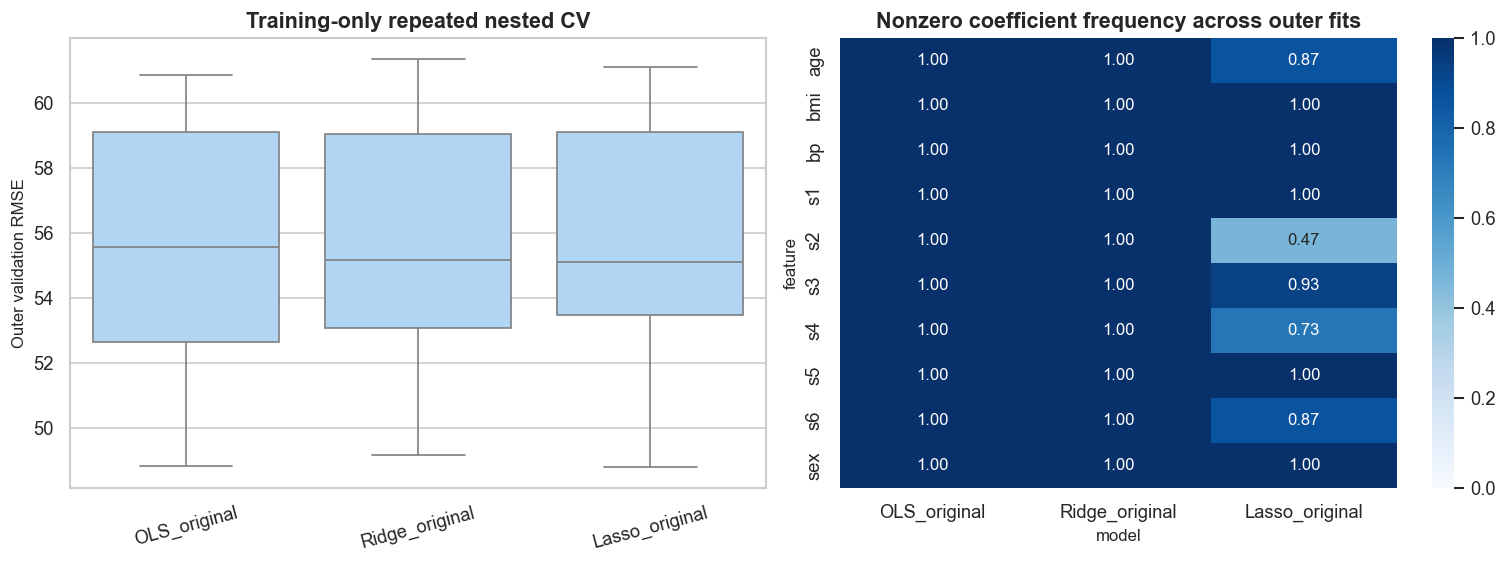

Coefficient spread and selection frequencies above measure sensitivity to training resamples. They do not demonstrate a universal advantage for regularization, and correlated variables can exchange coefficient weight. The original-feature ranking is effectively close; prefer a modest claim over asserting that one method is conclusively superior.

**Measured stability finding:** Neither retuned Ridge nor retuned Lasso has a lower mean per-feature coefficient SD than OLS in this experiment. The earlier blanket claim of improved coefficient stability is therefore not supported by this check. Tuning alpha adds another source of variation; these results concern the fitted tuning procedures, not a theorem about every penalty strength.

In [368]:
stability_models = ['OLS_original', 'Ridge_original', 'Lasso_original']
outer_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE + 100)
reference_scale = X_train.std(ddof=0).to_numpy()
stability_score_rows, stability_coef_rows, stability_warning_rows = [], [], []
for fold, (outer_fit, outer_valid) in enumerate(outer_cv.split(X_train), 1):
    fit_x, valid_x = X_train.iloc[outer_fit], X_train.iloc[outer_valid]
    fit_y, valid_y = y_train.iloc[outer_fit], y_train.iloc[outer_valid]
    assert set(fit_x.index).isdisjoint(frozen_test_indices)
    assert set(valid_x.index).isdisjoint(frozen_test_indices)
    inner_cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + fold)
    for name in stability_models:
        spec = model_specs[name]
        nested = GridSearchCV(clone(spec['estimator']), spec['param_grid'],
                              scoring='neg_root_mean_squared_error', cv=inner_cv,
                              n_jobs=-1, refit=True)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            nested.fit(fit_x, fit_y)
        stability_warning_rows.extend({'fold': fold, 'model': name, 'warning': str(w.message)}
                                      for w in caught)
        fitted = nested.best_estimator_
        coef_reference = (fitted.named_steps['model'].coef_ /
                          fitted.named_steps['scaler'].scale_ * reference_scale)
        stability_score_rows.append({
            'fold': fold, 'model': name,
            'rmse': regression_metrics(valid_y, fitted.predict(valid_x))['RMSE'],
            'chosen_alpha': nested.best_params_.get('model__alpha', np.nan),
        })
        for feature, coefficient in zip(X_train.columns, coef_reference):
            stability_coef_rows.append({'fold': fold, 'model': name, 'feature': feature,
                                        'coefficient_reference_sd': coefficient,
                                        'selected': abs(coefficient) > 1e-8})
stability_scores = pd.DataFrame(stability_score_rows)
stability_coefficients = pd.DataFrame(stability_coef_rows)
stability_summary = stability_scores.groupby('model').agg(
    outer_rmse_mean=('rmse', 'mean'), outer_rmse_std=('rmse', 'std'),
    outer_evaluations=('rmse', 'size'),
).reindex(stability_models)
paired_scores = stability_scores.pivot(index='fold', columns='model', values='rmse')
paired_rows = []
for name in stability_models[1:]:
    delta = paired_scores[name] - paired_scores['OLS_original']
    paired_rows.append({'comparison': name + ' minus OLS', 'mean_rmse_difference': delta.mean(),
                       'difference_std': delta.std(), 'better_than_OLS_folds': int((delta < 0).sum()),
                       'outer_folds': len(delta)})
paired_stability = pd.DataFrame(paired_rows)
coef_stability = stability_coefficients.groupby(['model', 'feature']).agg(
    coefficient_mean=('coefficient_reference_sd', 'mean'),
    coefficient_std=('coefficient_reference_sd', 'std'),
    selection_frequency=('selected', 'mean'),
).reset_index()
stability_summary['mean_feature_coefficient_std'] = (
    coef_stability.groupby('model')['coefficient_std'].mean()
)
display(stability_summary)
display(paired_stability)
display(coef_stability)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=stability_scores, x='model', y='rmse', color='#A5D8FF', ax=axes[0])
axes[0].set(title='Training-only repeated nested CV', xlabel='', ylabel='Outer validation RMSE')
axes[0].tick_params(axis='x', rotation=15)
sns.heatmap(coef_stability.pivot(index='feature', columns='model', values='selection_frequency').reindex(columns=stability_models),
            annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues', ax=axes[1])
axes[1].set_title('Nonzero coefficient frequency across outer fits')
plt.tight_layout()
plt.show()
display(Markdown(
    'Coefficient spread and selection frequencies above measure sensitivity to training resamples. '
    'They do not demonstrate a universal advantage for regularization, and correlated variables can '
    'exchange coefficient weight. The original-feature ranking is effectively close; prefer a modest '
    'claim over asserting that one method is conclusively superior.'
))
lower_spread_models = [name for name in stability_models[1:]
                      if stability_summary.loc[name, 'mean_feature_coefficient_std'] <
                         stability_summary.loc['OLS_original', 'mean_feature_coefficient_std']]
if not lower_spread_models:
    stability_interpretation = (
        'Neither retuned Ridge nor retuned Lasso has a lower mean per-feature coefficient SD than '
        'OLS in this experiment. The earlier blanket claim of improved coefficient stability is '
        'therefore not supported by this check. Tuning alpha adds another source of variation; '
        'these results concern the fitted tuning procedures, not a theorem about every penalty strength.'
    )
else:
    stability_interpretation = (
        'Lower mean per-feature coefficient SD than OLS was observed for ' + ', '.join(lower_spread_models)
        + '. This is conditional on these folds, grids, and representation; it is not a universal guarantee.'
    )
display(Markdown('**Measured stability finding:** ' + stability_interpretation))
protocol_events.append('nested_stability_study_completed_without_test_rows')


In [369]:
def get_split_for_feature_set(feature_set):
    if feature_set == "engineered":
        return X_train_engineered, X_test_engineered
    return X_train, X_test


fitted_models = {}
cv_rows = []
test_rows = []

for name, spec in model_specs.items():
    X_train_used, X_test_used = get_split_for_feature_set(spec["feature_set"])
    grid = GridSearchCV(
        estimator=spec["estimator"],
        param_grid=spec["param_grid"],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    grid.fit(X_train_used, y_train)
    fitted_models[name] = grid

    best_index = grid.best_index_
    cv_rmse = -grid.best_score_
    train_rmse = -grid.cv_results_["mean_train_score"][best_index]
    cv_std = grid.cv_results_["std_test_score"][best_index]
    cv_rows.append({
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "best_params": grid.best_params_,
        "cv_rmse_mean": cv_rmse,
        "cv_rmse_std": cv_std,
        "cv_train_rmse": train_rmse,
        "generalization_gap": cv_rmse - train_rmse,
    })

    y_pred = grid.best_estimator_.predict(X_test_used)
    test_rows.append({
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "best_params": grid.best_params_,
        **regression_metrics(y_test, y_pred),
    })

cv_summary = pd.DataFrame(cv_rows).sort_values("cv_rmse_mean").reset_index(drop=True)
test_results = pd.DataFrame(test_rows).sort_values("RMSE").reset_index(drop=True)

display(cv_summary)
display(test_results)

,model,family,feature_set,best_params,cv_rmse_mean,cv_rmse_std,cv_train_rmse,generalization_gap
0,Lasso_original,regularized linear,original,{'model__alpha': 0.1467799267622069},55.3488,2.3480,53.4064,1.9424
1,ElasticNet_original,regularized linear,original,"{'model__alpha': 0.03162277660168379, 'model__l1_ratio': 0.9}",55.3687,2.3688,53.3796,1.9891
2,Ridge_original,regularized linear,original,{'model__alpha': 1.0},55.3742,2.3732,53.3703,2.0039
3,OLS_original,linear,original,{},55.3946,2.3615,53.3461,2.0485
4,OLS_engineered,feature engineered,engineered,{},55.4160,2.5573,52.1128,3.3032
5,Ridge_engineered,feature engineered,engineered,{'model__alpha': 0.001},55.4162,2.5541,52.1128,3.3034
6,Lasso_engineered,feature engineered,engineered,{'model__alpha': 0.001},55.4217,2.5481,52.1129,3.3088
7,Lasso_poly2,polynomial degree 2,original,{'model__alpha': 3.1622776601683795},55.9712,1.9072,52.9185,3.0527
8,GradientBoosting,nonlinear ensemble,original,"{'learning_rate': 0.08, 'max_depth': 1, 'n_estimators': 180, 'subsample': 0.8}",56.6300,2.3023,46.4975,10.1325
9,Ridge_poly2,polynomial degree 2,original,{'model__alpha': 81.61400793251826},56.8867,1.6728,50.9885,5.8982


,model,family,feature_set,best_params,RMSE,MAE,R2
0,Lasso_poly2,polynomial degree 2,original,{'model__alpha': 3.1622776601683795},50.6853,41.2744,0.5151
1,Ridge_poly2,polynomial degree 2,original,{'model__alpha': 81.61400793251826},51.3381,41.1884,0.5025
2,GradientBoosting,nonlinear ensemble,original,"{'learning_rate': 0.08, 'max_depth': 1, 'n_estimators': 180, 'subsample': 0.8}",52.7024,41.6082,0.4758
3,Lasso_poly3,polynomial degree 3,original,{'model__alpha': 6.812920690579608},52.9417,43.8946,0.4710
4,Lasso_engineered,feature engineered,engineered,{'model__alpha': 0.001},53.0119,41.9639,0.4696
5,Ridge_engineered,feature engineered,engineered,{'model__alpha': 0.001},53.0131,41.9628,0.4696
6,OLS_engineered,feature engineered,engineered,{},53.0133,41.9611,0.4695
7,RandomForest,nonlinear ensemble,original,"{'max_depth': None, 'min_samples_leaf': 8, 'n_estimators': 300}",53.0500,42.7141,0.4688
8,Lasso_original,regularized linear,original,{'model__alpha': 0.1467799267622069},53.6857,42.8152,0.4560
9,ElasticNet_original,regularized linear,original,"{'model__alpha': 0.03162277660168379, 'model__l1_ratio': 0.9}",53.7406,42.8146,0.4549


In [370]:
assert cv_summary.loc[0, 'model'] == locked_model_name
assert fitted_models[locked_model_name].best_params_ == locked_params
locked_test_features = (X_test_engineered if model_specs[locked_model_name]['feature_set'] == 'engineered'
                        else X_test)
np.testing.assert_allclose(
    fitted_models[locked_model_name].predict(locked_test_features),
    locked_model.predict(locked_test_features), rtol=1e-9, atol=1e-9,
)
protocol_events.append('final_test_audit_after_locked_selection')


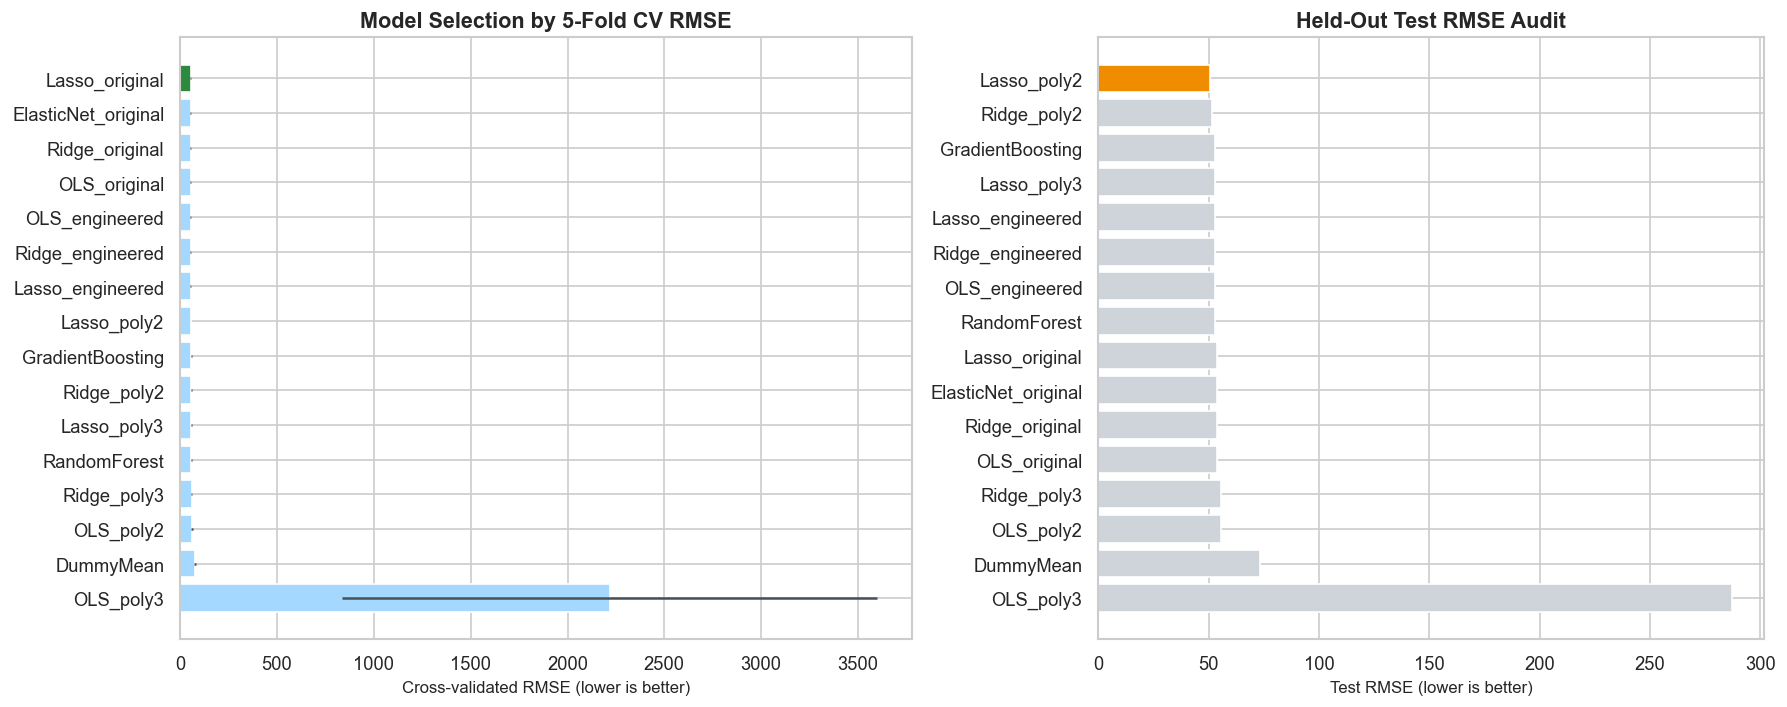


    **Honest selected model:** `Lasso_original` because it has the lowest training-set cross-validated RMSE.

    **Best held-out model in the audit table:** `Lasso_poly2`. This is reported transparently, but the model recommendation is based on cross-validation rather than test-set shopping.
    

In [371]:
selected_model_name = cv_summary.loc[0, "model"]
heldout_best_model_name = test_results.loc[0, "model"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})

cv_plot = cv_summary.sort_values("cv_rmse_mean", ascending=False)
axes[0].barh(
    cv_plot["model"],
    cv_plot["cv_rmse_mean"],
    xerr=cv_plot["cv_rmse_std"],
    color=[PALETTE["green"] if m == selected_model_name else "#A5D8FF" for m in cv_plot["model"]],
    ecolor=PALETTE["gray"],
)
axes[0].set_title("Model Selection by 5-Fold CV RMSE")
axes[0].set_xlabel("Cross-validated RMSE (lower is better)")
axes[0].set_ylabel("")

test_plot = test_results.sort_values("RMSE", ascending=False)
axes[1].barh(
    test_plot["model"],
    test_plot["RMSE"],
    color=[PALETTE["amber"] if m == heldout_best_model_name else "#CED4DA" for m in test_plot["model"]],
)
axes[1].set_title("Held-Out Test RMSE Audit")
axes[1].set_xlabel("Test RMSE (lower is better)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

display(Markdown(
    f"""
    **Honest selected model:** `{selected_model_name}` because it has the lowest training-set cross-validated RMSE.

    **Best held-out model in the audit table:** `{heldout_best_model_name}`. This is reported transparently, but the model recommendation is based on cross-validation rather than test-set shopping.
    """
))

## 9. Final Test Evaluation of the Selected Model

After choosing the model using cross-validation, we evaluate it once on the held-out test set. The diagnostic plots below are based on this selected model.

In [372]:
selected_spec = model_specs[selected_model_name]
selected_grid = fitted_models[selected_model_name]
X_train_selected, X_test_selected = get_split_for_feature_set(selected_spec["feature_set"])
y_pred_selected = selected_grid.best_estimator_.predict(X_test_selected)
selected_metrics = regression_metrics(y_test, y_pred_selected)

selected_result_table = pd.DataFrame([{
    "selected_model": selected_model_name,
    "feature_set": selected_spec["feature_set"],
    "best_params": selected_grid.best_params_,
    **selected_metrics,
}])
display(selected_result_table)

display(Markdown(
    f"""
    On the held-out test set, `{selected_model_name}` achieves **RMSE = {selected_metrics['RMSE']:.2f}**, **MAE = {selected_metrics['MAE']:.2f}**, and **R2 = {selected_metrics['R2']:.3f}**.
    """
))

,selected_model,feature_set,best_params,RMSE,MAE,R2
0,Lasso_original,original,{'model__alpha': 0.1467799267622069},53.6857,42.8152,0.456



    On the held-out test set, `Lasso_original` achieves **RMSE = 53.69**, **MAE = 42.82**, and **R2 = 0.456**.
    

### Preserved full-dataset audit, after final selection

The original loading/data-dictionary/audit and split-summary cells are retained verbatim below. Their target statistics are displayed only after the model decision and final evaluation. Re-loading the same
data here does not refit a model or change any features, parameters, or recommendation.


In [373]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

feature_descriptions = {
    "age": "Age",
    "sex": "Sex indicator",
    "bmi": "Body mass index",
    "bp": "Average blood pressure",
    "s1": "Total serum cholesterol",
    "s2": "Low-density lipoproteins",
    "s3": "High-density lipoproteins",
    "s4": "Total cholesterol / HDL ratio",
    "s5": "Log serum triglycerides",
    "s6": "Blood sugar level",
}

data_dictionary = pd.DataFrame({
    "feature": list(feature_descriptions.keys()),
    "meaning": list(feature_descriptions.values()),
    "role": ["Predictor"] * len(feature_descriptions),
})

dataset_audit = pd.DataFrame({
    "item": [
        "Number of observations",
        "Number of original predictors",
        "Missing values in predictors",
        "Missing values in target",
        "Target mean",
        "Target standard deviation",
        "Target minimum",
        "Target maximum",
    ],
    "value": [
        X.shape[0],
        X.shape[1],
        int(X.isna().sum().sum()),
        int(y.isna().sum()),
        float(y.mean()),
        float(y.std()),
        float(y.min()),
        float(y.max()),
    ],
})

display(data_dictionary)
display(dataset_audit)
display(X.head())

,feature,meaning,role
0,age,Age,Predictor
1,sex,Sex indicator,Predictor
2,bmi,Body mass index,Predictor
3,bp,Average blood pressure,Predictor
4,s1,Total serum cholesterol,Predictor
5,s2,Low-density lipoproteins,Predictor
6,s3,High-density lipoproteins,Predictor
7,s4,Total cholesterol / HDL ratio,Predictor
8,s5,Log serum triglycerides,Predictor
9,s6,Blood sugar level,Predictor


,item,value
0,Number of observations,442.0000
1,Number of original predictors,10.0000
2,Missing values in predictors,0.0000
3,Missing values in target,0.0000
4,Target mean,152.1335
5,Target standard deviation,77.0930
6,Target minimum,25.0000
7,Target maximum,346.0000


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466


In [374]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train_engineered = add_engineered_features(X_train)
X_test_engineered = add_engineered_features(X_test)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "subset": ["Training", "Test"],
    "rows": [len(X_train), len(X_test)],
    "share": [len(X_train) / len(X), len(X_test) / len(X)],
    "target_mean": [float(y_train.mean()), float(y_test.mean())],
    "target_std": [float(y_train.std()), float(y_test.std())],
})
display(split_summary)

,subset,rows,share,target_mean,target_std
0,Training,353,0.7986,153.7365,78.0619
1,Test,89,0.2014,145.7753,73.2008


In [375]:
assert tuple(X_train.index) == frozen_train_indices
assert tuple(X_test.index) == frozen_test_indices
protocol_events.append('original_full_audit_and_split_summary_preserved_after_evaluation')


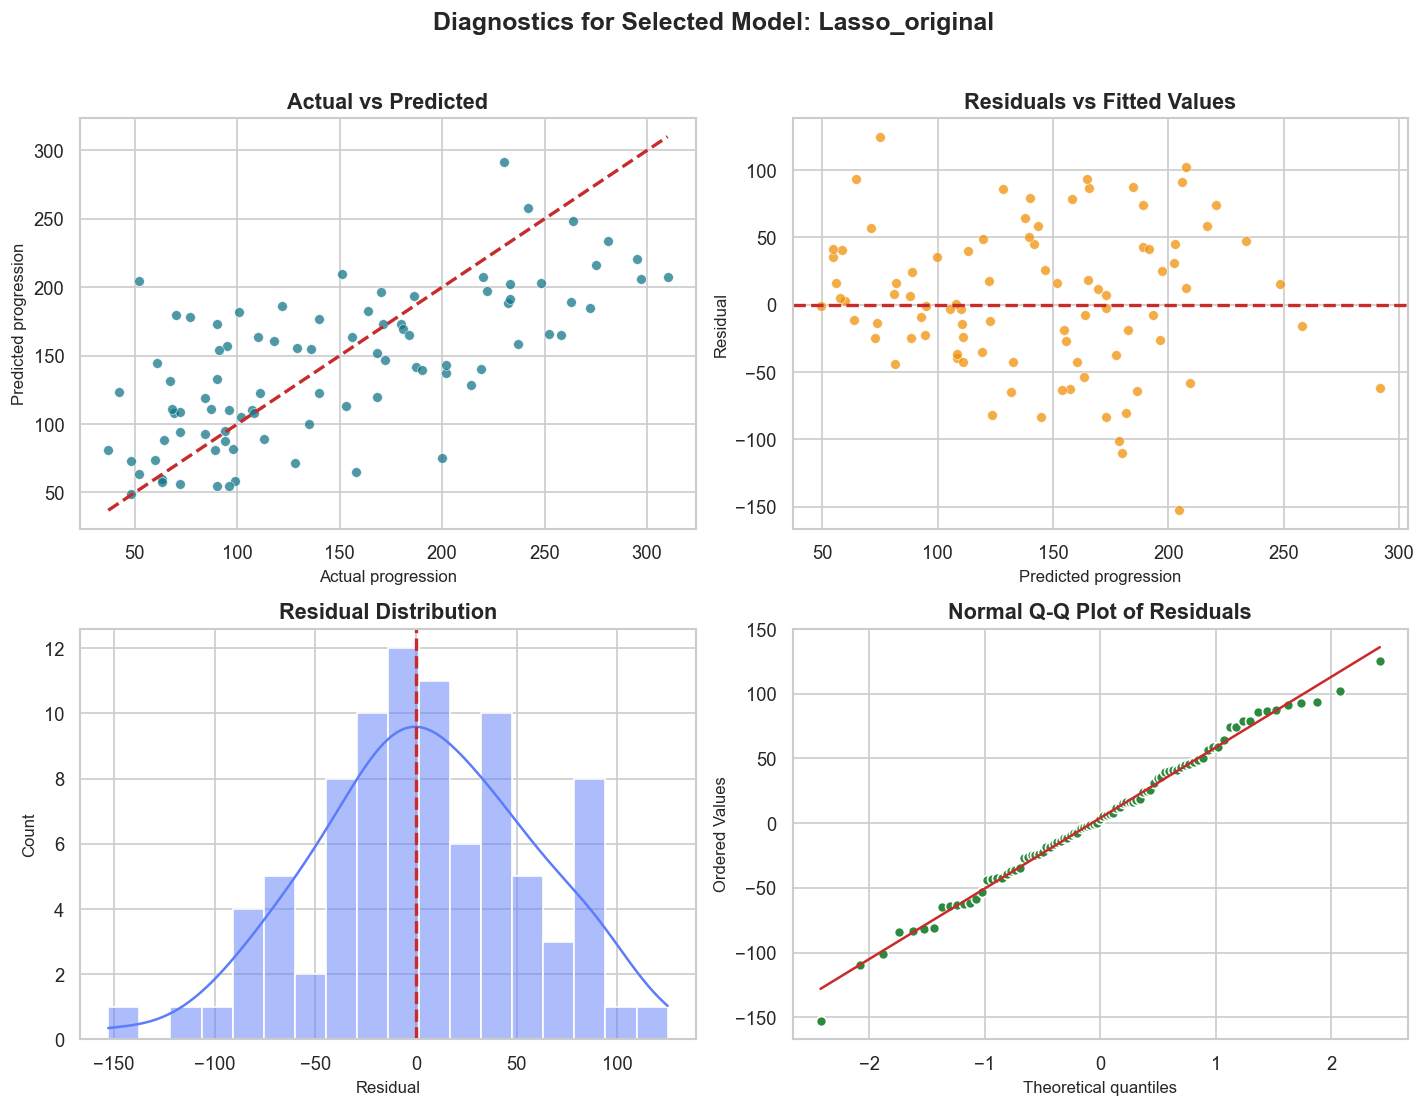

In [376]:
residuals = y_test - y_pred_selected

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

lims = [
    min(float(y_test.min()), float(y_pred_selected.min())),
    max(float(y_test.max()), float(y_pred_selected.max())),
]
axes[0].scatter(y_test, y_pred_selected, alpha=0.72, s=34, color=PALETTE["teal"], edgecolor="white", linewidth=0.4)
axes[0].plot(lims, lims, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual progression")
axes[0].set_ylabel("Predicted progression")

axes[1].scatter(y_pred_selected, residuals, alpha=0.72, s=34, color=PALETTE["amber"], edgecolor="white", linewidth=0.4)
axes[1].axhline(0, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs Fitted Values")
axes[1].set_xlabel("Predicted progression")
axes[1].set_ylabel("Residual")

sns.histplot(residuals, kde=True, bins=18, color=PALETTE["indigo"], edgecolor="white", ax=axes[2])
axes[2].axvline(0, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[2].set_title("Residual Distribution")
axes[2].set_xlabel("Residual")
axes[2].set_ylabel("Count")

stats.probplot(residuals, dist="norm", plot=axes[3])
axes[3].get_lines()[0].set_markerfacecolor(PALETTE["green"])
axes[3].get_lines()[0].set_markeredgecolor("white")
axes[3].get_lines()[1].set_color(PALETTE["red"])
axes[3].set_title("Normal Q-Q Plot of Residuals")

fig.suptitle(f"Diagnostics for Selected Model: {selected_model_name}", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Interpretation of the diagnostic plots

The identity line shows prediction error, not a fitted regression relationship. A concentration of
predictions toward the middle of the target range can cause overprediction of lower scores and
underprediction of higher scores. The table below quantifies this on the final audit.
Residual-versus-fitted and Q-Q plots help identify patterns or tail departures; neither proves that
the errors satisfy all modelling assumptions. Residual normality is not required simply to compute RMSE.


In [377]:
diagnostic_frame = pd.DataFrame({'actual': y_test, 'predicted': y_pred_selected,
                                 'residual_actual_minus_predicted': residuals})
diagnostic_frame['actual_target_band'] = pd.qcut(diagnostic_frame['actual'], 4,
                                                labels=['lowest quarter', 'middle-low', 'middle-high', 'highest quarter'])
diagnostic_summary = diagnostic_frame.groupby('actual_target_band', observed=True).agg(
    cases=('actual', 'size'), mean_actual=('actual', 'mean'), mean_predicted=('predicted', 'mean'),
    mean_residual=('residual_actual_minus_predicted', 'mean'),
)
display(diagnostic_summary)
display(Markdown(
    f"The mean test residual is **{residuals.mean():.2f}** (actual minus predicted). "
    f"In the highest target quarter it is **{diagnostic_summary.iloc[-1]['mean_residual']:.2f}**; "
    'positive residuals mean underprediction. These are post-selection descriptions, not instructions '
    'to retune against the test set. The sample is small and the model is not a clinical decision rule.'
))


,cases,mean_actual,mean_predicted,mean_residual
actual_target_band,,,,
lowest quarter,23,65.2609,103.9962,-38.7353
middle-low,22,103.7273,118.8342,-15.1069
middle-high,23,169.3043,148.3989,20.9055
highest quarter,21,252.2381,200.1888,52.0493


The mean test residual is **3.94** (actual minus predicted). In the highest target quarter it is **52.05**; positive residuals mean underprediction. These are post-selection descriptions, not instructions to retune against the test set. The sample is small and the model is not a clinical decision rule.

## 10. Interpretability

For models with coefficients, we look at the coefficient values to understand which variables are contributing more. we also use permutation importance because it gives another view of feature importance and can be used across different model types.

,feature,coefficient,abs_coefficient
0,s5,28.6527,28.6527
1,s1,-27.0137,27.0137
2,bmi,25.9122,25.9122
3,bp,16.5911,16.5911
4,s2,11.2079,11.2079
5,sex,-11.1933,11.1933
6,s4,10.4001,10.4001
7,s6,2.3934,2.3934
8,age,1.6918,1.6918
9,s3,-0.0000,0.0000


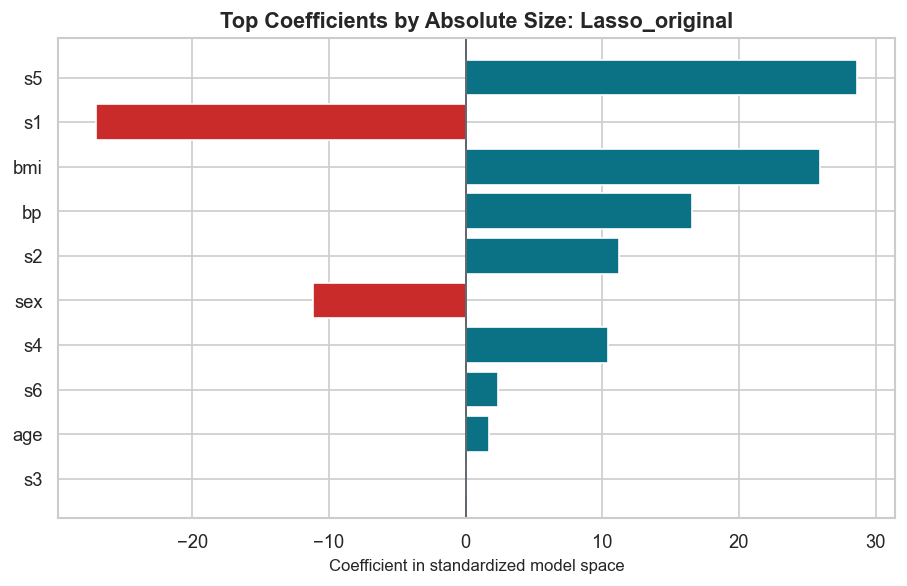

In [378]:
def feature_names_for_model(model_name):
    spec = model_specs[model_name]
    estimator = fitted_models[model_name].best_estimator_
    if spec["feature_set"] == "engineered":
        base_names = np.array(X_train_engineered.columns)
    else:
        base_names = np.array(X_train.columns)
    if isinstance(estimator, Pipeline) and "poly" in estimator.named_steps:
        return estimator.named_steps["poly"].get_feature_names_out(base_names)
    return base_names


def coefficient_table_for_model(model_name):
    estimator = fitted_models[model_name].best_estimator_
    model = estimator.named_steps["model"] if isinstance(estimator, Pipeline) and "model" in estimator.named_steps else estimator
    coefs = getattr(model, "coef_", None)
    if coefs is None:
        return None
    names = feature_names_for_model(model_name)
    return (
        pd.DataFrame({"feature": names, "coefficient": coefs})
        .assign(abs_coefficient=lambda df: df["coefficient"].abs())
        .sort_values("abs_coefficient", ascending=False)
        .reset_index(drop=True)
    )


selected_coef_table = coefficient_table_for_model(selected_model_name)
if selected_coef_table is not None:
    display(selected_coef_table.head(15))

    coef_plot_df = selected_coef_table.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    colors = [PALETTE["red"] if v < 0 else PALETTE["teal"] for v in coef_plot_df["coefficient"]]
    ax.barh(coef_plot_df["feature"], coef_plot_df["coefficient"], color=colors)
    ax.axvline(0, color=PALETTE["gray"], linewidth=1)
    ax.set_title(f"Top Coefficients by Absolute Size: {selected_model_name}")
    ax.set_xlabel("Coefficient in standardized model space")
    ax.set_ylabel("")
    plt.show()
else:
    display(Markdown(f"`{selected_model_name}` does not expose linear coefficients. Use permutation importance below."))

### Coefficient selection across all required representations

This directly addresses assignment section 4.4. Compare OLS, Ridge, and Lasso on original, manual,
degree-2, and degree-3 features. Coefficients are expressed in each fitted pipeline's standardized
feature units. Compare methods within a representation; coefficient norms across different-dimensional
representations do not have a common simple interpretation. Nonzero counts use tolerance `1e-8`.

Ridge generally shrinks rather than explicitly selects terms; Lasso can set them exactly to zero.
Correlated or algebraically redundant predictors make individual OLS coefficients non-unique or unstable.


,model,representation,method,features,alpha,nonzero_coefficients,zero_coefficients,coefficient_l2_norm,largest_absolute_coefficient
0,OLS_original,Original,OLS,10,NaN,10,0,7.1630e+01,s1
1,Ridge_original,Original,Ridge,10,1.0000,10,0,6.0909e+01,s1
2,Lasso_original,Original,Lasso,10,0.1468,9,1,5.3526e+01,s5
3,OLS_engineered,Manual engineered,OLS,19,NaN,19,0,2.9470e+02,s2
4,Ridge_engineered,Manual engineered,Ridge,19,0.0010,19,0,2.9362e+02,s2
5,Lasso_engineered,Manual engineered,Lasso,19,0.0010,17,2,2.9397e+02,s2
6,OLS_poly2,Polynomial degree 2,OLS,65,NaN,65,0,1.3111e+03,s1
7,Ridge_poly2,Polynomial degree 2,Ridge,65,81.6140,65,0,3.6658e+01,bmi
8,Lasso_poly2,Polynomial degree 2,Lasso,65,3.1623,15,50,3.6326e+01,bmi
9,OLS_poly3,Polynomial degree 3,OLS,285,NaN,285,0,1.3684e+06,s1 s2


**Original: leading coefficients from each method**

,OLS,Ridge,Lasso
feature,,,
s1,-44.4489,-34.6720,-27.0137
s5,35.1612,31.3784,28.6527
bmi,25.6071,25.7327,25.9122
s2,24.6410,17.0531,11.2079
bp,16.8289,16.7343,16.5911
s4,13.1388,11.7643,10.4001
sex,-11.5118,-11.4482,-11.1933


,OLS,Ridge,Lasso
feature,,,
s1,-44.4489,-34.672,-27.0137
s5,35.1612,31.3784,28.6527
bmi,25.6071,25.7327,25.9122
s2,24.641,17.0531,11.2079
bp,16.8289,16.7343,16.5911
s4,13.1388,11.7643,10.4001
sex,-11.5118,-11.4482,-11.1933
s3,7.67698,3.36991,-0
s6,2.35136,2.45814,2.39336


**Lasso retains 9/10 terms:** s5, s1, bmi, bp, s2, sex, s4, s6, age

...

**Lasso retains 15/65 terms:** bmi, s5, bp, s3, sex^2, age sex, bmi^2, bmi bp, s6^2, age bp, age s5, s6, age s2, bmi s6, sex

**Polynomial degree 3: leading coefficients from each method**

,OLS,Ridge,Lasso
feature,,,
s1 s2,-949317.1387,0.1540,-0.0000
s1^2,615832.4934,0.1520,-0.0000
s2^2,378017.4018,0.1185,-0.0000
s1 s3,-332134.1916,0.8033,0.0000
s2 s3,250657.4523,-0.1700,0.0000
s1 s2 s5,192616.7503,0.8587,0.0000
bmi,702.9341,5.2787,0.0000
sex^2 bmi,696.3601,5.2265,23.6494
s5,18288.9190,4.8527,17.8176


,OLS,Ridge,Lasso
feature,,,
s1 s2,-949317,0.15397,-0
s1^2,615832,0.152002,-0
s2^2,378017,0.118534,-0
s1 s3,-332134,0.803344,0
s2 s3,250657,-0.169954,0
s1 s2 s5,192617,0.858654,0
bp s1,-183023,0.210484,0
bp s2,157681,-0.0576965,-0
s1^2 s5,-146950,0.770901,0


**Lasso retains 9/285 terms:** sex^2 bmi, s5, sex^2 bp, s3, bmi^3, age^2 sex, bp^3, s3 s6^2, bmi^2

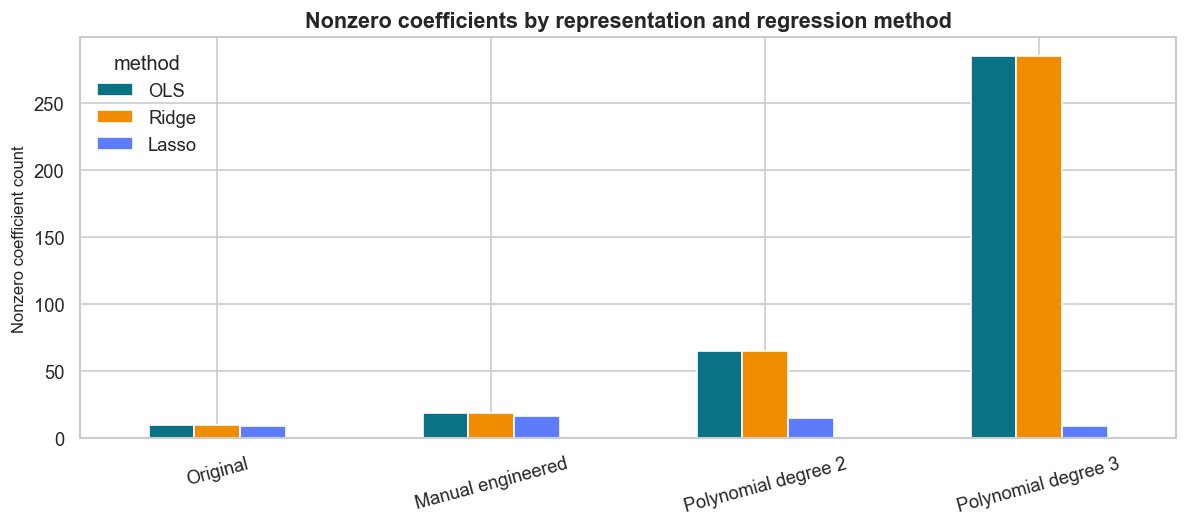

In the original-feature Lasso, the table identifies which serum terms are removed. A zero coefficient is a conditional modelling result, not proof of no marginal association or no biological relevance. Across expanded sets, stronger sparsity controls the number of active terms. Compare the retained terms with the prediction scores before claiming a better representation.

In [379]:
representations = {'original': 'Original', 'engineered': 'Manual engineered',
                   'poly2': 'Polynomial degree 2', 'poly3': 'Polynomial degree 3'}
required_model_names = [f'{method}_{suffix}' for suffix in representations
                        for method in ['OLS', 'Ridge', 'Lasso']]
coefficient_tables, coefficient_rows = {}, []
for name in required_model_names:
    table = coefficient_table_for_model(name)
    coefficient_tables[name] = table
    method, suffix = name.split('_', 1)
    coefficient_rows.append({
        'model': name, 'representation': representations[suffix], 'method': method,
        'features': len(table), 'alpha': fitted_models[name].best_params_.get('model__alpha', np.nan),
        'nonzero_coefficients': int((table.coefficient.abs() > 1e-8).sum()),
        'zero_coefficients': int((table.coefficient.abs() <= 1e-8).sum()),
        'coefficient_l2_norm': float(np.linalg.norm(table.coefficient)),
        'largest_absolute_coefficient': table.iloc[0]['feature'],
    })
coefficient_comparison = pd.DataFrame(coefficient_rows)
display(coefficient_comparison)
for suffix, label in representations.items():
    names = [f'{method}_{suffix}' for method in ['OLS', 'Ridge', 'Lasso']]
    joined = pd.concat({name.split('_')[0]: coefficient_tables[name].set_index('feature')['coefficient']
                        for name in names}, axis=1)
    # Include leading terms from each method, not only OLS's ranking.
    leading_terms = list(dict.fromkeys(term for name in names
                                     for term in coefficient_tables[name].head(6)['feature']))
    display(Markdown(f'**{label}: leading coefficients from each method**'))
    display(joined.loc[leading_terms])
    display(HTML('<details><summary>Show all coefficients: ' + label + '</summary>'
                 + joined.to_html(float_format=lambda x: f'{x:.6g}') + '</details>'))
    lasso_table = coefficient_tables[f'Lasso_{suffix}']
    retained = lasso_table.loc[lasso_table.coefficient.abs() > 1e-8, 'feature'].tolist()
    dropped = lasso_table.loc[lasso_table.coefficient.abs() <= 1e-8, 'feature'].tolist()
    display(Markdown(f"**Lasso retains {len(retained)}/{len(lasso_table)} terms:** " + ', '.join(retained)))
    display(HTML('<details><summary>Zeroed Lasso terms</summary><p>' + ', '.join(dropped) + '</p></details>'))
fig, ax = plt.subplots(figsize=(10, 4.5))
selection_plot = coefficient_comparison.pivot(index='representation', columns='method', values='nonzero_coefficients')
selection_plot = selection_plot.reindex(index=list(representations.values()), columns=['OLS', 'Ridge', 'Lasso'])
selection_plot.plot.bar(ax=ax, color=[PALETTE['teal'], PALETTE['amber'], PALETTE['indigo']])
ax.set(title='Nonzero coefficients by representation and regression method',
       xlabel='', ylabel='Nonzero coefficient count')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()
display(Markdown(
    'In the original-feature Lasso, the table identifies which serum terms are removed. A zero '
    'coefficient is a conditional modelling result, not proof of no marginal association or no '
    'biological relevance. Across expanded sets, stronger sparsity controls the number of active '
    'terms. Compare the retained terms with the prediction scores before claiming a better representation.'
))


## Polynomial complexity, rank, and overfitting

Ten inputs expand to 65 degree-2 terms and 285 degree-3 terms (excluding the intercept). Only 353
training observations are available, and a five-fold CV fit uses 282 or 283 of them. A binary predictor
creates redundant powers: for values `a` and `b`, `sex² = (a+b)sex - ab`; higher powers and related
interactions also introduce dependencies. The two manual linear composites are combinations of existing
columns, so they add no independent linear information to OLS.

High-dimensional unregularized OLS can both overfit and become numerically sensitive. Retaining this
failed model is informative; its exact large error should not be treated as a stable generalization estimate.


,representation,columns,training_rows,numerical_rank,redundant_columns,condition_number,retained_subspace_condition
0,Original,10,353,10,0,2.0733e+01,2.0733e+01
1,Manual engineered,19,353,17,2,8.8610e+15,8.6020e+01
2,Polynomial degree 2,65,353,64,1,7.5860e+15,6.6035e+03
3,Polynomial degree 3,285,353,274,11,2.8691e+16,5.0403e+06


,degree,method,features,nonzero_coefficients,training_rmse,cv_rmse,cv_std,gap,test_rmse
0,1,OLS,10,10,53.3461,55.3946,2.3615,2.0485,53.8534
1,1,Ridge,10,10,53.3703,55.3742,2.3732,2.0039,53.7775
2,1,Lasso,10,9,53.4064,55.3488,2.3480,1.9424,53.6857
3,2,OLS,65,65,47.6347,62.5048,4.4120,14.8701,55.6420
4,2,Ridge,65,65,50.9885,56.8867,1.6728,5.8982,51.3381
5,2,Lasso,65,15,52.9185,55.9712,1.9072,3.0527,50.6853
6,3,OLS,285,285,10.8262,2216.9178,1381.7767,2206.0915,287.1342
7,3,Ridge,285,285,50.1806,59.3297,3.3862,9.1491,55.4036
8,3,Lasso,285,9,54.9279,57.3391,2.9907,2.4111,52.9417


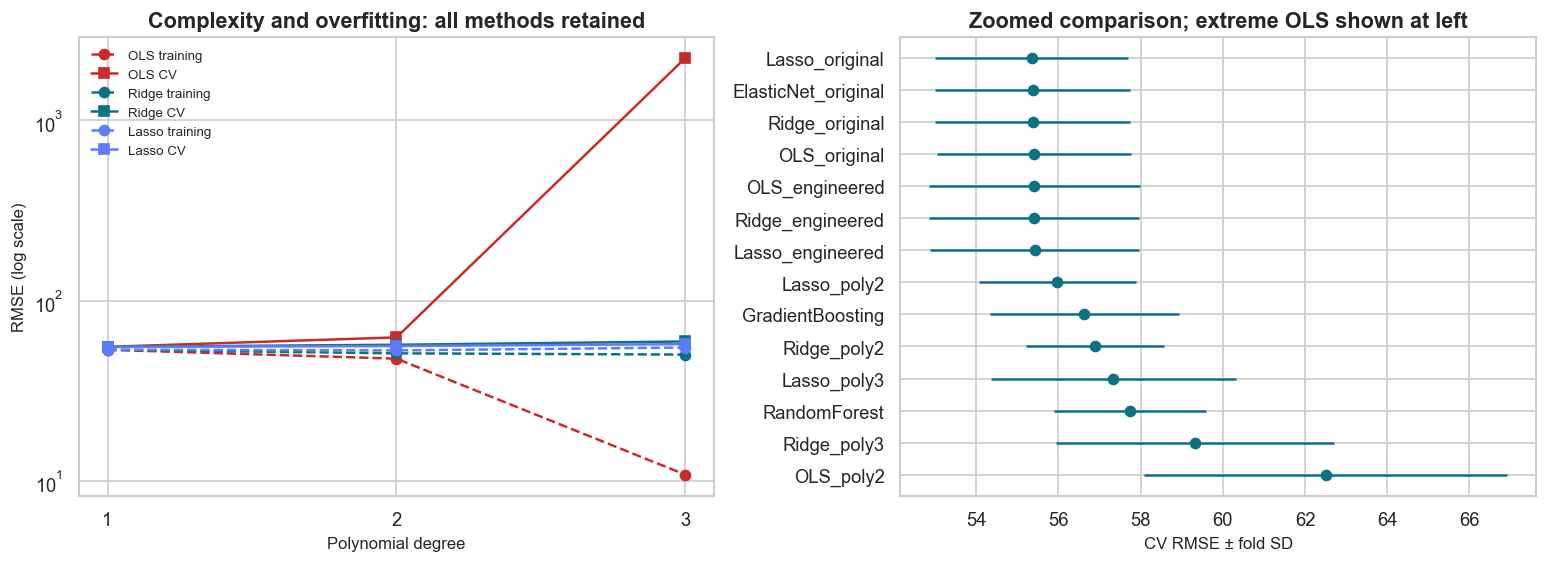

**Cubic OLS:** training RMSE **10.83**, CV RMSE **2216.92**, gap **2206.09**, and test RMSE **287.13**. Low fitting error accompanied by very high validation error is severe overfitting. Rank deficiency also makes coefficient interpretation and exact numerical reproduction fragile. Ridge and Lasso control this failure, but their expanded models do not automatically beat original features in CV.

**Historical reproducibility note:** the original saved cubic OLS CV/test RMSE values were **2216.9178 / 287.1342**; a prior review rerun gave **1402.1769 / 278.9423**. The current table is recomputed in this run. The failure is qualitatively consistent; the exact cause of the numerical difference cannot be isolated because the original library versions were not recorded. Avoid interpreting small changes in this failed model as scientific improvement.

In [380]:
design_rows = []
for suffix, label in representations.items():
    model_name = f'OLS_{suffix}'
    train_data, _ = get_split_for_feature_set(model_specs[model_name]['feature_set'])
    matrix = fitted_models[model_name].best_estimator_[:-1].transform(train_data)
    centered_matrix = matrix - matrix.mean(axis=0)
    singular_values = np.linalg.svd(centered_matrix, compute_uv=False)
    rank = np.linalg.matrix_rank(centered_matrix)
    # Report an effective condition number on the numerically retained singular subspace as well.
    design_rows.append({'representation': label, 'columns': matrix.shape[1],
                        'training_rows': matrix.shape[0], 'numerical_rank': int(rank),
                        'redundant_columns': int(matrix.shape[1] - rank),
                        'condition_number': float(np.linalg.cond(centered_matrix)),
                        'retained_subspace_condition': float(singular_values[0] / singular_values[rank - 1])})
design_diagnostics = pd.DataFrame(design_rows)
display(design_diagnostics)
degree_rows = []
for degree, suffix in [(1, 'original'), (2, 'poly2'), (3, 'poly3')]:
    for method in ['OLS', 'Ridge', 'Lasso']:
        name = f'{method}_{suffix}'
        c = cv_summary.loc[cv_summary.model == name].iloc[0]
        t = test_results.loc[test_results.model == name].iloc[0]
        count = coefficient_comparison.loc[coefficient_comparison.model == name].iloc[0]
        degree_rows.append({'degree': degree, 'method': method, 'features': int(count['features']),
                            'nonzero_coefficients': int(count['nonzero_coefficients']),
                            'training_rmse': c.cv_train_rmse, 'cv_rmse': c.cv_rmse_mean,
                            'cv_std': c.cv_rmse_std, 'gap': c.generalization_gap,
                            'test_rmse': t.RMSE})
degree_comparison = pd.DataFrame(degree_rows)
display(degree_comparison)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for method, color in zip(['OLS', 'Ridge', 'Lasso'], [PALETTE['red'], PALETTE['teal'], PALETTE['indigo']]):
    part = degree_comparison[degree_comparison.method == method]
    axes[0].plot(part.degree, part.training_rmse, '--o', color=color, label=method + ' training')
    axes[0].plot(part.degree, part.cv_rmse, '-s', color=color, label=method + ' CV')
axes[0].set(yscale='log', xticks=[1, 2, 3], xlabel='Polynomial degree', ylabel='RMSE (log scale)',
            title='Complexity and overfitting: all methods retained')
axes[0].legend(fontsize=8)
zoom = cv_summary[~cv_summary.model.isin(['OLS_poly3', 'DummyMean'])].sort_values('cv_rmse_mean')
axes[1].errorbar(zoom.cv_rmse_mean, zoom.model, xerr=zoom.cv_rmse_std, fmt='o', color=PALETTE['teal'])
axes[1].invert_yaxis()
axes[1].set(xlabel='CV RMSE ± fold SD', title='Zoomed comparison; extreme OLS shown at left')
plt.tight_layout()
plt.show()
cubic = degree_comparison[(degree_comparison.method == 'OLS') & (degree_comparison.degree == 3)].iloc[0]
display(Markdown(
    f"**Cubic OLS:** training RMSE **{cubic.training_rmse:.2f}**, CV RMSE **{cubic.cv_rmse:.2f}**, "
    f"gap **{cubic.gap:.2f}**, and test RMSE **{cubic.test_rmse:.2f}**. "
    'Low fitting error accompanied by very high validation error is severe overfitting. Rank deficiency '
    'also makes coefficient interpretation and exact numerical reproduction fragile. Ridge and Lasso '
    'control this failure, but their expanded models do not automatically beat original features in CV.'
))
display(Markdown(
    '**Historical reproducibility note:** the original saved cubic OLS CV/test RMSE values were '
    '**2216.9178 / 287.1342**; a prior review rerun gave **1402.1769 / 278.9423**. '
    'The current table is recomputed in this run. The failure is qualitatively consistent; the exact '
    'cause of the numerical difference cannot be isolated because the original library versions were '
    'not recorded. Avoid interpreting small changes in this failed model as scientific improvement.'
))


,feature,rmse_increase_when_permuted,std
0,s5,14.8618,2.7707
1,bmi,10.1089,2.5094
2,s1,8.3639,2.5045
3,sex,3.2553,1.0762
4,s2,3.0710,1.1154
5,bp,2.3060,1.9805
6,s4,1.0737,0.9328
7,s6,0.1721,0.1889
8,s3,0.0000,0.0000
9,age,-0.1843,0.2325


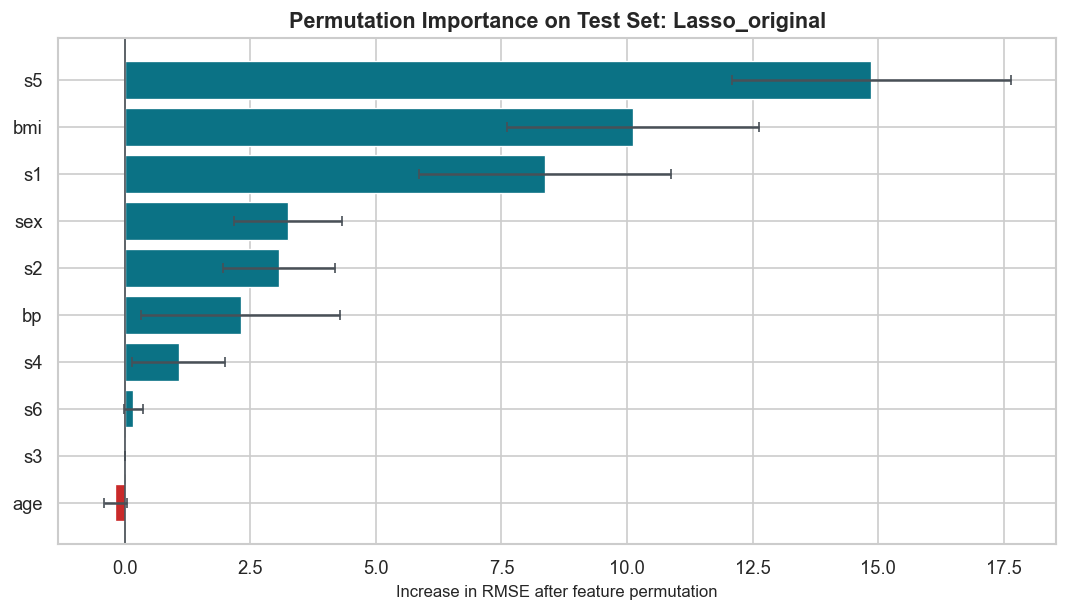

In [381]:
perm = permutation_importance(
    selected_grid.best_estimator_,
    X_test_selected,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_table = (
    pd.DataFrame({
        "feature": X_test_selected.columns,
        "rmse_increase_when_permuted": perm.importances_mean,
        "std": perm.importances_std,
    })
    .sort_values("rmse_increase_when_permuted", ascending=False)
    .reset_index(drop=True)
)
display(permutation_table.head(12))

fig, ax = plt.subplots(figsize=(9, 5.2))
perm_plot = permutation_table.head(10).iloc[::-1]
bar_colors = [
    PALETTE["red"] if value < 0 else PALETTE["teal"]
    for value in perm_plot["rmse_increase_when_permuted"]
]

ax.barh(
    perm_plot["feature"],
    perm_plot["rmse_increase_when_permuted"],
    color=bar_colors,
    edgecolor="white",
    linewidth=0.8,
)
ax.errorbar(
    perm_plot["rmse_increase_when_permuted"],
    perm_plot["feature"],
    xerr=perm_plot["std"],
    fmt="none",
    ecolor=PALETTE["gray"],
    elinewidth=1.5,
    capsize=3,
)
ax.axvline(0, color=PALETTE["gray"], linewidth=1)
ax.set_title(f"Permutation Importance on Test Set: {selected_model_name}")
ax.set_xlabel("Increase in RMSE after feature permutation")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

> **Importance caveat:** correlated predictors can share or substitute predictive information,
> so permutation importance and coefficients need not agree with marginal correlations. The repeated
> training analysis above measures coefficient sensitivity directly. Test permutation importance is
> post-selection interpretation only; it is not used to drop features or refit the chosen model.


## 11. Error Analysis

Here we look at the largest prediction errors on the test set. Some large errors are expected because this is a small clinical dataset and many real-world factors affecting disease progression are not present in the data.

,actual,predicted,residual,absolute_error,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
56,52.0,204.7222,-152.7222,152.7222,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
77,200.0,75.1038,124.8962,124.8962,-0.0963,-0.0446,-0.0364,-0.0745,-0.0387,-0.0276,0.0155,-0.0395,-0.0741,-0.0011
211,70.0,179.9936,-109.9936,109.9936,0.0926,-0.0446,0.0369,0.0219,-0.0250,-0.0167,0.0008,-0.0395,-0.0225,-0.0218
9,310.0,207.6979,102.3021,102.3021,-0.0709,-0.0446,0.0391,-0.0332,-0.0126,-0.0345,-0.0250,-0.0026,0.0677,-0.0135
209,77.0,178.4105,-101.4105,101.4105,0.0381,0.0507,-0.0181,0.0666,-0.0511,-0.0167,-0.0765,0.0343,-0.0119,-0.0135
131,158.0,64.6292,93.3708,93.3708,-0.0963,-0.0446,-0.0698,-0.0676,-0.0195,-0.0107,0.0155,-0.0395,-0.0469,-0.0798
395,258.0,164.8761,93.1239,93.1239,-0.0600,-0.0446,0.0013,-0.0298,-0.0071,-0.0217,0.0118,-0.0026,0.0318,-0.0549
113,297.0,205.8930,91.1070,91.1070,0.0199,0.0507,0.0143,0.0632,0.0149,0.0203,-0.0471,0.0343,0.0467,0.0900
354,272.0,184.7855,87.2145,87.2145,-0.0237,0.0507,0.0455,0.0219,0.1099,0.0889,0.0008,0.0343,0.0742,0.0611
78,252.0,165.5814,86.4186,86.4186,0.0054,-0.0446,-0.0579,-0.0229,-0.0676,-0.0683,-0.0544,-0.0026,0.0429,-0.0839


,test_cases,share
absolute_error,,
0-25,35,0.3933
25-50,23,0.2584
50-75,14,0.1573
75-100,12,0.1348
100+,5,0.0562


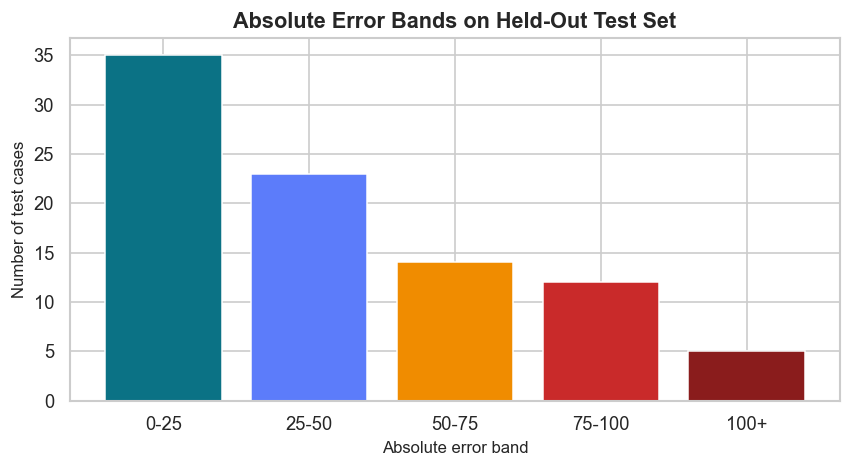

In [382]:
prediction_audit = (
    pd.DataFrame({
        "actual": y_test,
        "predicted": y_pred_selected,
        "residual": residuals,
        "absolute_error": np.abs(residuals),
    })
    .join(X_test)
    .sort_values("absolute_error", ascending=False)
)

display(prediction_audit.head(10))

error_bands = pd.cut(
    prediction_audit["absolute_error"],
    bins=[0, 25, 50, 75, 100, np.inf],
    labels=["0-25", "25-50", "50-75", "75-100", "100+"],
    include_lowest=True,
)
error_band_table = error_bands.value_counts().sort_index().to_frame("test_cases")
error_band_table["share"] = error_band_table["test_cases"] / len(prediction_audit)
display(error_band_table)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
error_colors = [
    PALETTE["teal"],
    PALETTE["indigo"],
    PALETTE["amber"],
    PALETTE["red"],
    "#8A1C1C",
]
ax.bar(
    error_band_table.index.astype(str),
    error_band_table["test_cases"],
    color=error_colors,
    edgecolor="white",
    linewidth=0.9,
)
ax.set_title("Absolute Error Bands on Held-Out Test Set")
ax.set_xlabel("Absolute error band")
ax.set_ylabel("Number of test cases")
plt.tight_layout()
plt.show()

## 12. Assignment Readiness Gauge

This table is a quick check to make sure the notebook covers the main parts expected in the assignment: problem framing, EDA, feature engineering, model comparison, evaluation, interpretation, and conclusion.

In [383]:
coverage_table = pd.DataFrame({
    "aspect": [
        "Problem framing",
        "Dataset understanding",
        "EDA and visualization",
        "Preprocessing protocol",
        "Feature engineering",
        "Model comparison",
        "Hyperparameter tuning",
        "Final test evaluation",
        "Diagnostics",
        "Interpretability",
        "Limitations and conclusion",
    ],
    "coverage": [
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
    ],
    "evidence": [
        "Regression objective, target definition, research questions.",
        "Data dictionary, shape, missing-value audit, target scale.",
        "Target histogram, feature distributions, correlation heatmap, scatter plots.",
        "Train-test split, CV on training only, scaling inside pipelines.",
        "Squared terms, interactions, lipid/metabolic proxies, polynomial features.",
        "Dummy, OLS, Ridge, Lasso, ElasticNet, polynomial, Random Forest, Gradient Boosting.",
        "GridSearchCV with 5-fold KFold and RMSE scoring.",
        "Held-out RMSE, MAE, R2 reported after model selection.",
        "Actual-vs-predicted, residuals, residual distribution, Q-Q plot.",
        "Coefficients where available and permutation importance for selected model.",
        "Honest-selection note, clinical caution, small-sample limitations.",
    ],
})
display(coverage_table)

,aspect,coverage,evidence
0,Problem framing,Complete,"Regression objective, target definition, research questions."
1,Dataset understanding,Complete,"Data dictionary, shape, missing-value audit, target scale."
2,EDA and visualization,Complete,"Target histogram, feature distributions, correlation heatmap, scatter plots."
3,Preprocessing protocol,Complete,"Train-test split, CV on training only, scaling inside pipelines."
4,Feature engineering,Complete,"Squared terms, interactions, lipid/metabolic proxies, polynomial features."
5,Model comparison,Complete,"Dummy, OLS, Ridge, Lasso, ElasticNet, polynomial, Random Forest, Gradient Boosting."
6,Hyperparameter tuning,Complete,GridSearchCV with 5-fold KFold and RMSE scoring.
7,Final test evaluation,Complete,"Held-out RMSE, MAE, R2 reported after model selection."
8,Diagnostics,Complete,"Actual-vs-predicted, residuals, residual distribution, Q-Q plot."
9,Interpretability,Complete,Coefficients where available and permutation importance for selected model.


> **Scope of the original readiness gauge:** the retained table above is a narrative checklist.
> The executable checks and evidence table at the end verify the additions. “Complete” means the
> assignment topic is addressed, not that the dataset proves a stable clinical or causal conclusion.


## 13. Research Questions

This section directly answers the six research questions from the assignment. The earlier sections show the calculations and plots, and here we summarize the answers in one place.

In [384]:
def model_row(df, model_name):
    return df.loc[df["model"] == model_name].iloc[0]

ols_cv = model_row(cv_summary, "OLS_original")
ols_test = model_row(test_results, "OLS_original")
lasso_cv = model_row(cv_summary, "Lasso_original")
ridge_cv = model_row(cv_summary, "Ridge_original")
selected_test = model_row(test_results, selected_model_name)

expanded_families = ["feature engineered", "polynomial degree 2", "polynomial degree 3"]
expanded_cv_results = cv_summary[cv_summary["family"].isin(expanded_families)].copy()
expanded_test_results = test_results[test_results["family"].isin(expanded_families)].copy()
best_expanded_cv = expanded_cv_results.iloc[0]
best_expanded_test = expanded_test_results.iloc[0]
heldout_best_row = test_results.iloc[0]

strongest_original = corr_with_target.abs().sort_values(ascending=False).head(6).index.tolist()
strongest_original_text = ", ".join(
    f"{feature} (r={corr_with_target[feature]:.3f})" for feature in strongest_original
)

research_question_answers = pd.DataFrame([
    {
        "No.": 1,
        "Research question": "Which baseline characteristics have the strongest statistical association with disease progression?",
        "Direct answer": (
            f"The strongest original baseline associations are {strongest_original_text}. "
            f"Among engineered variables, metabolic_risk_index is strongest (r={engineered_corr.loc[0, 'correlation_with_target']:.3f})."
        ),
        "Evidence used": "Feature-target correlations, scatter plots, engineered-feature correlation chart.",
    },
    {
        "No.": 2,
        "Research question": "How well can a linear model explain the variation in the target?",
        "Direct answer": (
            f"OLS_original gives CV RMSE={ols_cv['cv_rmse_mean']:.2f}, test RMSE={ols_test['RMSE']:.2f}, "
            f"test MAE={ols_test['MAE']:.2f}, and test R2={ols_test['R2']:.3f}. This is useful but still limited explanatory power."
        ),
        "Evidence used": "OLS cross-validation row and held-out test metrics.",
    },
    {
        "No.": 3,
        "Research question": "Does regularization improve generalization when predictors are correlated?",
        "Direct answer": (
            f"Regularization improves generalization slightly and stabilizes the model under multicollinearity: "
            f"Lasso CV RMSE={lasso_cv['cv_rmse_mean']:.2f}, Ridge CV RMSE={ridge_cv['cv_rmse_mean']:.2f}, "
            f"versus OLS CV RMSE={ols_cv['cv_rmse_mean']:.2f}. The improvement is small, but VIF values for serum variables are high, so regularization is justified."
        ),
        "Evidence used": "VIF table plus OLS/Ridge/Lasso cross-validation comparison.",
    },
    {
        "No.": 4,
        "Research question": "Do nonlinear models capture relationships that a linear model cannot?",
        "Direct answer": (
            f"Expanded features do help in the held-out audit: the best expanded model by test RMSE is {best_expanded_test['model']} "
            f"with test RMSE={best_expanded_test['RMSE']:.2f} and R2={best_expanded_test['R2']:.3f}. "
            f"However, by cross-validation the best expanded model is {best_expanded_cv['model']} with CV RMSE={best_expanded_cv['cv_rmse_mean']:.2f}, "
            f"so nonlinear gains must be interpreted carefully because higher-degree features can overfit."
        ),
        "Evidence used": "Manual engineered features, degree-2 and degree-3 polynomial comparisons, held-out audit.",
    },
    {
        "No.": 5,
        "Research question": "How sensitive are the conclusions to the choice of model?",
        "Direct answer": (
            "The broad predictor story is fairly stable for BMI, s5, blood pressure, and lipid-related variables. "
            f"The exact best model is sensitive: the CV-selected model is {selected_model_name}, while the lowest held-out test RMSE appears for {heldout_best_row['model']}."
        ),
        "Evidence used": "CV ranking, test ranking, coefficient table, permutation importance.",
    },
    {
        "No.": 6,
        "Research question": "Which model provides the best balance between predictive accuracy and interpretability?",
        "Direct answer": (
            f"{selected_model_name} provides the best balance. It has the best CV RMSE ({cv_summary.loc[0, 'cv_rmse_mean']:.2f}), "
            f"good held-out performance (RMSE={selected_test['RMSE']:.2f}, R2={selected_test['R2']:.3f}), and interpretable coefficients. "
            f"{heldout_best_row['model']} has the lowest held-out test RMSE but is less straightforward to explain and was not selected by CV."
        ),
        "Evidence used": "CV-selected model, test metrics, coefficient sparsity, interpretability discussion.",
    },
])

pd.set_option("display.max_colwidth", 180)
display(research_question_answers)

,No.,Research question,Direct answer,Evidence used
0,1,Which baseline characteristics have the strongest statistical association with disease progression?,"The strongest original baseline associations are bmi (r=0.605), s5 (r=0.552), bp (r=0.445), s4 (r=0.425), s6 (r=0.390), s3 (r=-0.384). Among engineered variables, metabolic_ris...","Feature-target correlations, scatter plots, engineered-feature correlation chart."
1,2,How well can a linear model explain the variation in the target?,"OLS_original gives CV RMSE=55.39, test RMSE=53.85, test MAE=42.79, and test R2=0.453. This is useful but still limited explanatory power.",OLS cross-validation row and held-out test metrics.
2,3,Does regularization improve generalization when predictors are correlated?,"Regularization improves generalization slightly and stabilizes the model under multicollinearity: Lasso CV RMSE=55.35, Ridge CV RMSE=55.37, versus OLS CV RMSE=55.39. The improv...",VIF table plus OLS/Ridge/Lasso cross-validation comparison.
3,4,Do nonlinear models capture relationships that a linear model cannot?,"Expanded features do help in the held-out audit: the best expanded model by test RMSE is Lasso_poly2 with test RMSE=50.69 and R2=0.515. However, by cross-validation the best ex...","Manual engineered features, degree-2 and degree-3 polynomial comparisons, held-out audit."
4,5,How sensitive are the conclusions to the choice of model?,"The broad predictor story is fairly stable for BMI, s5, blood pressure, and lipid-related variables. The exact best model is sensitive: the CV-selected model is Lasso_original,...","CV ranking, test ranking, coefficient table, permutation importance."
5,6,Which model provides the best balance between predictive accuracy and interpretability?,"Lasso_original provides the best balance. It has the best CV RMSE (55.35), good held-out performance (RMSE=53.69, R2=0.456), and interpretable coefficients. Lasso_poly2 has the...","CV-selected model, test metrics, coefficient sparsity, interpretability discussion."


In [385]:
def metric_row(frame, name):
    return frame.loc[frame.model == name].iloc[0]

ols_c = metric_row(cv_summary, 'OLS_original')
lasso_c = metric_row(cv_summary, 'Lasso_original')
ridge_c = metric_row(cv_summary, 'Ridge_original')
ols_t = metric_row(test_results, 'OLS_original')
selected_t = metric_row(test_results, locked_model_name)
train_associations = ', '.join(f'{name} (r={corr_with_target[name]:.3f})'
                               for name in corr_with_target.abs().nlargest(6).index)
best_expanded_cv_row = cv_summary[cv_summary.family.isin(
    ['feature engineered', 'polynomial degree 2', 'polynomial degree 3'])].iloc[0]
best_expanded_test_row = test_results[test_results.family.isin(
    ['feature engineered', 'polynomial degree 2', 'polynomial degree 3'])].iloc[0]
paired_text = '; '.join(
    f"{r['comparison']}: mean RMSE difference {r['mean_rmse_difference']:.3f}, "
    f"better on {int(r['better_than_OLS_folds'])}/{int(r['outer_folds'])} outer splits"
    for r in paired_stability.to_dict('records')
)
spread_text = '; '.join(f'{name}: {row.mean_feature_coefficient_std:.3f}'
                        for name, row in stability_summary.iterrows())
revised_answers = [
    ('1. Strongest baseline associations',
     f'Training-only correlations identify {train_associations}. These describe marginal association, '
     'not causation. Conditional coefficients and permutation importance can differ because the '
     'serum predictors are correlated.'),
    ('2. Linear-model explanatory power',
     f'Original-feature OLS has CV RMSE {ols_c.cv_rmse_mean:.2f}, test RMSE {ols_t.RMSE:.2f}, '
     f'MAE {ols_t.MAE:.2f}, and test R² {ols_t.R2:.3f}. This is useful predictive signal compared '
     'with the mean baseline, but substantial variation remains unexplained; this is not causal explanation.'),
    ('3. Regularization under correlated predictors',
     f'Lasso CV RMSE is {lasso_c.cv_rmse_mean:.4f}, Ridge {ridge_c.cv_rmse_mean:.4f}, '
     f'and OLS {ols_c.cv_rmse_mean:.4f}. The observed Lasso–OLS difference is only '
     f'{lasso_c.cv_rmse_mean - ols_c.cv_rmse_mean:.4f}. Repeated nested training validation gives '
     f'{paired_text}. Mean per-feature coefficient SD in common units is {spread_text}. '
     'These are empirical sensitivity summaries, not a significance test or proof of universal stability. '
     'The strongest evidence for regularization here is control of the expanded-model failure and sparsity. '
     + stability_interpretation),
    ('4. Nonlinear representation and overfitting',
     f'The best expanded model in training CV is {best_expanded_cv_row.model} '
     f'(RMSE {best_expanded_cv_row.cv_rmse_mean:.2f}); the lowest expanded-model test RMSE is '
     f'{best_expanded_test_row.model} ({best_expanded_test_row.RMSE:.2f}). '
     'The degree table shows why lower training error does not guarantee better validation performance. '
     'Cubic OLS is severely unstable; expanded regularized models are safer, but a test-set win alone '
     'does not establish reliable nonlinear improvement.'),
    ('5. Sensitivity to model choice',
     'Prediction ranking, retained terms, and coefficient allocations change with model and representation. '
     'The complete coefficient tables and repeated selection frequencies expose this sensitivity. '
     'Important marginal predictors do not necessarily retain the same conditional coefficient in every model. '
     'The test winner differs from the CV winner; use this as evidence of sampling/model sensitivity, '
     'not permission to select retrospectively on the test set.'),
    ('6. Accuracy versus interpretability',
     f'The pre-test rule selected {locked_model_name}, with test RMSE {selected_t.RMSE:.2f} '
     f'and R² {selected_t.R2:.3f}. It is a reasonable compact recommendation, but OLS and Ridge '
     'are competitive on the original representation. Small score differences do not prove an '
     'unambiguous best model. Prefer the simple model and explain its coefficients, uncertainty, '
     'and limitations rather than treating a marginal ranking as decisive.'),
]
for heading, answer in revised_answers:
    display(Markdown(f'**{heading}**\n\n{answer}'))


**1. Strongest baseline associations**

Training-only correlations identify bmi (r=0.605), s5 (r=0.552), bp (r=0.445), s4 (r=0.425), s6 (r=0.390), s3 (r=-0.384). These describe marginal association, not causation. Conditional coefficients and permutation importance can differ because the serum predictors are correlated.

**2. Linear-model explanatory power**

Original-feature OLS has CV RMSE 55.39, test RMSE 53.85, MAE 42.79, and test R² 0.453. This is useful predictive signal compared with the mean baseline, but substantial variation remains unexplained; this is not causal explanation.

**3. Regularization under correlated predictors**

Lasso CV RMSE is 55.3488, Ridge 55.3742, and OLS 55.3946. The observed Lasso–OLS difference is only -0.0458. Repeated nested training validation gives Ridge_original minus OLS: mean RMSE difference 0.123, better on 6/15 outer splits; Lasso_original minus OLS: mean RMSE difference 0.277, better on 6/15 outer splits. Mean per-feature coefficient SD in common units is OLS_original: 4.176; Ridge_original: 6.030; Lasso_original: 6.218. These are empirical sensitivity summaries, not a significance test or proof of universal stability. The strongest evidence for regularization here is control of the expanded-model failure and sparsity. Neither retuned Ridge nor retuned Lasso has a lower mean per-feature coefficient SD than OLS in this experiment. The earlier blanket claim of improved coefficient stability is therefore not supported by this check. Tuning alpha adds another source of variation; these results concern the fitted tuning procedures, not a theorem about every penalty strength.

**4. Nonlinear representation and overfitting**

The best expanded model in training CV is OLS_engineered (RMSE 55.42); the lowest expanded-model test RMSE is Lasso_poly2 (50.69). The degree table shows why lower training error does not guarantee better validation performance. Cubic OLS is severely unstable; expanded regularized models are safer, but a test-set win alone does not establish reliable nonlinear improvement.

**5. Sensitivity to model choice**

Prediction ranking, retained terms, and coefficient allocations change with model and representation. The complete coefficient tables and repeated selection frequencies expose this sensitivity. Important marginal predictors do not necessarily retain the same conditional coefficient in every model. The test winner differs from the CV winner; use this as evidence of sampling/model sensitivity, not permission to select retrospectively on the test set.

**6. Accuracy versus interpretability**

The pre-test rule selected Lasso_original, with test RMSE 53.69 and R² 0.456. It is a reasonable compact recommendation, but OLS and Ridge are competitive on the original representation. Small score differences do not prove an unambiguous best model. Prefer the simple model and explain its coefficients, uncertainty, and limitations rather than treating a marginal ranking as decisive.

### Short written synthesis

1. **Strongest baseline associations:** `bmi`, `s5`, `bp`, `s4`, `s3`, and `s6` are the strongest original-feature associations with disease progression. `s3` has a negative association, while the others are positive. The engineered `metabolic_risk_index` gives the strongest single engineered association.
2. **Linear-model explanatory power:** OLS explains a useful part of the variation, but not all of it. It is clearly better than the mean baseline, but the R2 value shows that a lot of variation is still left unexplained.
3. **Regularization:** Ridge, Lasso, and ElasticNet are useful here because some serum variables are highly correlated. The improvement over OLS is not very large, but regularization makes the model more stable and easier to trust.
4. **Nonlinear relationships:** Manual engineered features and polynomial degree-2/degree-3 features can reduce the held-out test error, but cross-validation does not clearly select the most complex models as the most reliable option. So there may be nonlinear signal, but there is also overfitting risk.
5. **Sensitivity:** The main story about important predictors is fairly stable, especially for BMI, s5, blood pressure, and lipid-related variables. However, the exact best model changes depending on whether we look at CV results or the test audit.
6. **Best balance:** `Lasso_original` is our final recommended model because it has the best cross-validation result, gives good test performance, and is easier to explain than polynomial or ensemble models.

## 14. Final Conclusion

Overall, the diabetes progression target has a clear but not perfect linear signal. BMI, `s5`, blood pressure, and cholesterol-related variables appear important throughout the analysis. The VIF results also show that some serum variables are strongly correlated, so regularized regression is a sensible choice.

The final recommendation is based on cross-validation rather than simply picking the model with the lowest test error. `Lasso_original` is a good balance because it performs well and remains interpretable. The polynomial models are useful to compare, but they are more complex and their improvement is not consistent enough in cross-validation.

So, this notebook covers the main assignment requirements: EDA, feature engineering, model comparison, regularization, final evaluation, diagnostics, interpretation, and the direct answers to the research questions.

In [386]:
selected_test_row = test_results.loc[test_results["model"] == selected_model_name].iloc[0]
heldout_best_row = test_results.iloc[0]

inline_summary = pd.DataFrame([
    {"item": "Observations", "value": int(X.shape[0])},
    {"item": "Original features", "value": int(X.shape[1])},
    {"item": "Engineered features considered", "value": int(X_engineered.shape[1])},
    {"item": "CV-selected model", "value": selected_model_name},
    {"item": "CV RMSE of selected model", "value": f"{cv_summary.loc[cv_summary['model'] == selected_model_name, 'cv_rmse_mean'].iloc[0]:.2f}"},
    {"item": "Selected model test RMSE", "value": f"{selected_test_row['RMSE']:.2f}"},
    {"item": "Selected model test MAE", "value": f"{selected_test_row['MAE']:.2f}"},
    {"item": "Selected model test R2", "value": f"{selected_test_row['R2']:.3f}"},
    {"item": "Lowest held-out test RMSE model", "value": heldout_best_row["model"]},
    {"item": "Lowest held-out test RMSE", "value": f"{heldout_best_row['RMSE']:.2f}"},
])

display(Markdown("**Inline-only final summary:** no charts, CSV files, or JSON files are saved outside this notebook."))
display(inline_summary)

**Inline-only final summary:** no charts, CSV files, or JSON files are saved outside this notebook.

,item,value
0,Observations,442
1,Original features,10
2,Engineered features considered,19
3,CV-selected model,Lasso_original
4,CV RMSE of selected model,55.35
5,Selected model test RMSE,53.69
6,Selected model test MAE,42.82
7,Selected model test R2,0.456
8,Lowest held-out test RMSE model,Lasso_poly2
9,Lowest held-out test RMSE,50.69


## Final revised synthesis

Feature representation and regularization must be considered together. More polynomial terms lower
the fitting error of OLS while introducing redundancy and a large validation gap. Ridge controls
coefficient magnitude; Lasso also removes terms. The coefficient and degree tables make these effects
explicit rather than inferring them from a single selected model.

On original features, the CV differences between OLS, Ridge, and Lasso are small. Repeated nested
training validation and coefficient variability quantify sensitivity, but overlapping folds and a small
dataset limit stronger inferential claims. The recommendation remains the model locked before test
predictions. The test-best polynomial model is a descriptive audit finding, not a replacement selection.

All EDA that informs this revised workflow uses training rows. Nevertheless, the same dataset and
test split were examined in an earlier version; no code change can erase that history. External data
or a prospectively untouched evaluation would be needed for a new independent confirmation. These
results are an educational regression study and do not support clinical or causal conclusions.


In [387]:
# ADDED: executable evidence that the revised notebook meets the central requirements.
assert set(eda_train_indices) == set(frozen_train_indices)
assert set(eda_train_indices).isdisjoint(frozen_test_indices)
assert len(required_model_names) == 12
assert all(name in fitted_models and name in coefficient_tables for name in required_model_names)
assert coefficient_comparison.loc[coefficient_comparison.model == 'OLS_poly2', 'features'].item() == 65
assert coefficient_comparison.loc[coefficient_comparison.model == 'OLS_poly3', 'features'].item() == 285
assert len(stability_scores) == 45 and stability_scores.groupby('model').size().eq(15).all()
assert len(coef_stability) == 30
assert selected_model_name == locked_model_name
assert protocol_events.index('model_and_parameters_locked_before_test_predictions') < protocol_events.index('final_test_audit_after_locked_selection')
assert len(revised_answers) == 6
assert all(np.isfinite(test_results[metric]).all() for metric in ['RMSE', 'MAE', 'R2'])
revision_evidence = pd.DataFrame([
    {'requirement': 'Training-only EDA and unchanged split', 'evidence': 'Index-disjointness assertions passed'},
    {'requirement': 'Pre-test model selection', 'evidence': 'Locked model, parameters, and predictions agree'},
    {'requirement': 'All OLS/Ridge/Lasso feature representations', 'evidence': '12 fitted models and coefficient tables'},
    {'requirement': 'Coefficient selection', 'evidence': 'Counts, retained/zeroed terms, full tables, and comparison plot'},
    {'requirement': 'Polynomial complexity and overfitting', 'evidence': '65/285 terms, rank diagnostics, train/CV/test degree table'},
    {'requirement': 'Empirical sensitivity', 'evidence': '45 outer scores, training-only nested tuning, 30 coefficient summaries'},
    {'requirement': 'Research questions and uncertainty', 'evidence': 'Six complete, qualified answers and revised synthesis'},
    {'requirement': 'Reproducibility', 'evidence': 'Environment versions, visible warnings, complete execution'},
])
display(revision_evidence)


,requirement,evidence
0,Training-only EDA and unchanged split,Index-disjointness assertions passed
1,Pre-test model selection,"Locked model, parameters, and predictions agree"
2,All OLS/Ridge/Lasso feature representations,12 fitted models and coefficient tables
3,Coefficient selection,"Counts, retained/zeroed terms, full tables, and comparison plot"
4,Polynomial complexity and overfitting,"65/285 terms, rank diagnostics, train/CV/test degree table"
5,Empirical sensitivity,"45 outer scores, training-only nested tuning, 30 coefficient summaries"
6,Research questions and uncertainty,"Six complete, qualified answers and revised synthesis"
7,Reproducibility,"Environment versions, visible warnings, complete execution"
